# Classification binaire d'ECG : normal ou pathologique

**Problématique.** À partir d'un électrocardiogramme 12 dérivations de 10 secondes (base publique PTB-XL v1.0.3, signaux échantillonnés à 500 Hz), prédire s'il est `NORMAL` ou `PATHOLOGICAL`, c'est-à-dire porteur d'au moins une des superclasses diagnostiques MI (infarctus du myocarde), STTC (anomalies du segment ST et de l'onde T), CD (troubles de la conduction) ou HYP (hypertrophie). Le modèle est un perceptron multicouche (MLP) nourri de 120 statistiques globales du signal.

**Contenu.** Ce notebook déroule le pipeline complet du projet, sans importer aucun autre fichier du dépôt : il part des seuls fichiers bruts de PTB-XL.

> fichiers bruts PTB-XL → étiquettes et partitions par patient → 120 caractéristiques par ECG → exploration → prétraitement → MLP (réglage, entraînement, seuil, validation croisée) → évaluation unique sur le test → analyse des erreurs → prédiction sur des ECG jamais vus

**Exécution.** *Kernel → Restart & Run All*. Il faut `numpy`, `pandas`, `scipy`, `wfdb`, `scikit-learn`, `torch`, `matplotlib` et `seaborn` : `python -m pip install -r requirements.txt` installe les versions utilisées par le projet.

- **Données.** PTB-XL v1.0.3, publiée par PhysioNet sous licence CC BY 4.0 :
    - page officielle : <https://physionet.org/content/ptb-xl/1.0.3/>
    - base complète, archive ZIP de 1,7 Go : <https://physionet.org/content/ptb-xl/get-zip/1.0.3/>
    - DOI : <https://doi.org/10.13026/kfzx-aw45>
- **Emplacement.** Le notebook lit la base dans `DOSSIER_PTBXL` (`data/raw/ptb-xl/` par défaut, comme le reste du dépôt). S'il y manque des fichiers, il télécharge uniquement ceux dont il a besoin depuis le miroir officiel de PhysioNet, environ 360 Mo pour 3 000 ECG ; un fichier déjà présent n'est jamais retéléchargé. Il n'écrit rien d'autre.
- **Nombre d'ECG.** Le notebook travaille sur un sous-échantillon stratifié de `N_ECG = 3000` ECG (20 % de la base) : l'exécution complète prend une dizaine de minutes sur un processeur ordinaire, sans GPU. Avec `N_ECG = None`, il utilise les 14 979 ECG du projet (un peu plus de 20 minutes) et retrouve les résultats de l'entraînement du projet (`results/binary/`) à quelques millièmes près.
- **Reproductibilité.** Le tirage du sous-échantillon et les entraînements sont déterministes (graines fixées). Les commentaires chiffrés correspondent à l'exécution enregistrée dans ce notebook, avec les paramètres par défaut.

**Plan.** 0. Paramètres · 1. Données et étiquettes · 2. Signaux ECG · 3. Extraction des caractéristiques · 4. Exploration · 5. Prétraitement · 6. Modèle et entraînement · 7. Évaluation sur le test · 8. Analyse des erreurs · 9. Prédiction sur un nouvel ECG · 10. Comparaison avec la base complète · 11. Conclusion

> Démonstrateur pédagogique : ces résultats ne constituent pas une validation clinique.

## 0. Paramètres

La cellule suivante est la seule à modifier. `N_ECG` règle le compromis entre durée d'exécution et précision des résultats. `DOSSIER_PTBXL` indique le dossier PTB-XL v1.0.3 à lire, celui qui contient `ptbxl_database.csv`, `scp_statements.csv` et `records500/`  ; les fichiers manquants y sont téléchargés.

In [1]:
# Paramètres de l'exécution : seule cellule à modifier.
from pathlib import Path

N_ECG = 3000                              # ECG utilisés (sous-échantillon stratifié) ; None = base complète (14 979 ECG)
GRAINE_ECHANTILLON = 42                   # graine du tirage du sous-échantillon
DOSSIER_PTBXL = Path("data/raw/ptb-xl")   # PTB-XL v1.0.3 : lu sur place, fichiers manquants téléchargés
TELECHARGER = True                        # autoriser le téléchargement des fichiers manquants

In [2]:
# Bibliothèques, constantes du projet et style des figures.
import ast
import random
import shutil
import sys
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import wfdb
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import kurtosis, skew
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

DEBUT_NOTEBOOK = time.perf_counter()

# Étiquettes : cinq superclasses diagnostiques PTB-XL, ramenées à deux classes.
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
PATHOLOGIES = SUPERCLASSES[1:]
CLASSES = ["NORMAL", "PATHOLOGICAL"]

# Partitions du projet : folds officiels PTB-XL, stratifiés et disjoints par patient.
PARTITIONS = {"train": [1, 2, 3, 4, 5], "validation": [10], "test": [6]}

# Signaux et caractéristiques : 12 dérivations × 10 statistiques = 120 variables.
FS, N_ECHANTILLONS = 500, 5000
DERIVATIONS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
STATISTIQUES = ["mean", "std", "rms", "median", "iqr", "min", "max", "skewness", "kurtosis", "line_length"]
CARACTERISTIQUES = [f"{derivation}_{stat}" for derivation in DERIVATIONS for stat in STATISTIQUES]

# Hyperparamètres du MLP du projet (configs/binary.json) et graines d'entraînement.
CONFIG = {"hidden_sizes": [128, 64], "dropout": 0.3, "learning_rate": 1e-3, "weight_decay": 1e-4,
          "batch_size": 128, "max_epochs": 200, "patience": 20, "num_threads": 4}
GRAINES = [0, 1, 2, 3, 4]
SEUILS = np.round(np.arange(1, 100) / 100, 2)  # seuils candidats sur la probabilité PATHOLOGICAL

# Palette bleu / orange vérifiée pour les daltonismes ; gris pour les repères (hasard).
BLEU, ORANGE, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
ENCRE, ENCRE_2 = "#0b0b0b", "#52514e"
COULEUR_CLASSE = {"NORMAL": BLEU, "PATHOLOGICAL": ORANGE}
SEQUENTIEL = LinearSegmentedColormap.from_list("bleus", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])
DIVERGENT = LinearSegmentedColormap.from_list("bleu_gris_rouge", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": ENCRE, "text.color": ENCRE,
    "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})


def moyenne_ecart(valeurs):
    """« moyenne ± écart-type » (écart-type d'échantillon), pour les tableaux de synthèse."""
    return f"{np.mean(valeurs):.4f} ± {np.std(valeurs, ddof=1):.4f}"


print(f"Python {sys.version.split()[0]} · NumPy {np.__version__} · pandas {pd.__version__} · "
      f"scikit-learn {sklearn.__version__} · PyTorch {torch.__version__} · wfdb {wfdb.__version__}")

Python 3.14.0 · NumPy 2.5.3 · pandas 2.3.3 · scikit-learn 1.9.1 · PyTorch 2.14.1+cpu · wfdb 4.3.1


## 1. Données et étiquettes

PTB-XL v1.0.3 réunit 21 799 ECG cliniques de 10 secondes, enregistrés sur 18 869 patients et annotés par des cardiologues avec des codes de la norme SCP-ECG. Ses auteurs ont réparti les patients en 10 *folds* stratifiés sur les diagnostics : tous les ECG d'un même patient sont dans le même fold.

*Source :* Wagner, P., Strodthoff, N., Bousseljot, R., Samek, W. et Schaeffter, T. (2022). PTB-XL, a large publicly available electrocardiography dataset (version 1.0.3). PhysioNet, licence CC BY 4.0. <https://doi.org/10.13026/kfzx-aw45>, téléchargement de la base complète : <https://physionet.org/content/ptb-xl/get-zip/1.0.3/>.

### 1.1 Fichiers de la base

Deux fichiers CSV décrivent la base : `ptbxl_database.csv` (une ligne par ECG : patient, âge, sexe, fold, codes SCP, chemin du signal) et `scp_statements.csv` (signification de chaque code SCP). La fonction ci-dessous vérifie leur présence et télécharge ce qui manque ; elle servira aussi pour les signaux (§ 1.6).

In [3]:
SOURCES = ("https://physionet-open.s3.amazonaws.com/ptb-xl/1.0.3/",  # miroir officiel PhysioNet (AWS Open Data)
           "https://physionet.org/files/ptb-xl/1.0.3/")               # site PhysioNet, plus lent


def telecharger_fichier(relatif):
    """Télécharge un fichier PTB-XL (chemin relatif à la racine de la base) en essayant chaque source."""
    destination = DOSSIER_PTBXL / relatif
    destination.parent.mkdir(parents=True, exist_ok=True)
    partiel = destination.with_name(destination.name + ".part")
    erreur = None
    for source in SOURCES:
        for essai in range(3):
            try:
                with urllib.request.urlopen(source + relatif, timeout=60) as reponse, open(partiel, "wb") as sortie:
                    attendu = int(reponse.headers.get("Content-Length", -1))
                    shutil.copyfileobj(reponse, sortie)
                if attendu >= 0 and partiel.stat().st_size != attendu:
                    raise OSError(f"fichier incomplet ({partiel.stat().st_size} octets sur {attendu})")
                partiel.replace(destination)  # le fichier n'apparaît qu'une fois complet
                return
            except OSError as exc:
                erreur = exc
                time.sleep(1 + essai)
    partiel.unlink(missing_ok=True)
    raise OSError(f"Téléchargement impossible : {relatif} ({erreur})")


def assurer_fichiers(relatifs):
    """Vérifie que les fichiers sont dans DOSSIER_PTBXL ; télécharge ceux qui manquent, 16 à la fois."""
    manquants = [relatif for relatif in relatifs if not (DOSSIER_PTBXL / relatif).is_file()]
    if not manquants:
        print(f"{len(relatifs)} fichiers présents dans {DOSSIER_PTBXL} : aucun téléchargement.")
        return
    if not TELECHARGER:
        raise FileNotFoundError(f"{len(manquants)} fichiers absents de {DOSSIER_PTBXL.resolve()} "
                                f"(par exemple {manquants[0]}) et TELECHARGER = False.")
    print(f"Téléchargement de {len(manquants)} fichiers vers {DOSSIER_PTBXL.resolve()}")
    debut = time.perf_counter()
    with ThreadPoolExecutor(max_workers=16) as executeur:
        taches = [executeur.submit(telecharger_fichier, relatif) for relatif in manquants]
        for n, tache in enumerate(as_completed(taches), 1):
            tache.result()
            if n % 1000 == 0 or n == len(taches):
                print(f"  {n} / {len(taches)} fichiers ({time.perf_counter() - debut:.0f} s)")


assurer_fichiers(["ptbxl_database.csv", "scp_statements.csv"])

2 fichiers présents dans data\raw\ptb-xl : aucun téléchargement.


### 1.2 Métadonnées

In [4]:
base = pd.read_csv(DOSSIER_PTBXL / "ptbxl_database.csv")
codes_scp = pd.read_csv(DOSSIER_PTBXL / "scp_statements.csv", index_col=0)
print(f"{len(base)} ECG, {base['patient_id'].nunique()} patients, {base.shape[1]} colonnes ; "
      f"{len(codes_scp)} codes SCP décrits")
base[["ecg_id", "patient_id", "age", "sex", "strat_fold", "filename_hr", "scp_codes"]].head()

21799 ECG, 18869 patients, 28 colonnes ; 71 codes SCP décrits


,ecg_id,patient_id,age,sex,strat_fold,filename_hr,scp_codes
0,1,15709.0,56.0,1,3,records500/00000/00001_hr,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,13243.0,19.0,0,2,records500/00000/00002_hr,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,20372.0,37.0,1,5,records500/00000/00003_hr,"{'NORM': 100.0, 'SR': 0.0}"
3,4,17014.0,24.0,0,3,records500/00000/00004_hr,"{'NORM': 100.0, 'SR': 0.0}"
4,5,17448.0,19.0,1,4,records500/00000/00005_hr,"{'NORM': 100.0, 'SR': 0.0}"


### 1.3 Des codes SCP à la classe binaire

Chaque ECG porte un dictionnaire `{code SCP : vraisemblance}`. `scp_statements.csv` rattache chaque code **diagnostique** à l'une des cinq superclasses `NORM`, `MI`, `STTC`, `CD` ou `HYP`. Les codes non diagnostiques (rythme, forme du tracé) sont ignorés, et tout code diagnostique présent compte, quelle que soit sa vraisemblance. Les ECG sans aucune des cinq superclasses sont écartés.

La cible binaire suit une règle simple, avec **priorité à la pathologie** :

- `PATHOLOGICAL` dès qu'au moins une des superclasses `MI`, `STTC`, `CD` ou `HYP` est présente ;
- `NORMAL` si `NORM` est présente et aucune des quatre autres.

C'est le seul encodage du projet : les 120 variables d'entrée sont toutes numériques.

In [5]:
# Codes SCP diagnostiques → superclasse.
diagnostiques = codes_scp[(codes_scp["diagnostic"] == 1) & codes_scp["diagnostic_class"].isin(SUPERCLASSES)]
code_vers_superclasse = diagnostiques["diagnostic_class"].to_dict()


def superclasses_presentes(texte_scp):
    """Indicateurs 0/1 des cinq superclasses d'un ECG ; tous les codes comptent, quelle que soit leur vraisemblance."""
    presentes = {code_vers_superclasse[c] for c in ast.literal_eval(texte_scp) if c in code_vers_superclasse}
    return [int(s in presentes) for s in SUPERCLASSES]


indicateurs = pd.DataFrame(base["scp_codes"].map(superclasses_presentes).tolist(),
                           columns=SUPERCLASSES, index=base.index)
ecg = pd.concat([base, indicateurs], axis=1)
sans_superclasse = ecg[SUPERCLASSES].sum(axis=1) == 0
ecg = ecg[~sans_superclasse].reset_index(drop=True)

# Règle binaire : la pathologie est prioritaire sur NORM.
ecg["label"] = ecg[PATHOLOGIES].any(axis=1).astype(np.int64)
ecg["classe"] = np.array(CLASSES)[ecg["label"]]

print(f"ECG sans aucune des cinq superclasses (écartés) : {sans_superclasse.sum()}")
print(f"ECG étiquetés                                   : {len(ecg)}")
display(diagnostiques["diagnostic_class"].value_counts().reindex(SUPERCLASSES).rename("codes SCP").to_frame().T)

# Vérification de la règle sur toute la base étiquetée.
pd.crosstab([ecg["NORM"].map({0: "NORM absent", 1: "NORM présent"}),
             ecg[PATHOLOGIES].any(axis=1).map({False: "aucune pathologie", True: "≥ 1 pathologie (MI, STTC, CD, HYP)"})],
            ecg["classe"])

ECG sans aucune des cinq superclasses (écartés) : 411
ECG étiquetés                                   : 21388


diagnostic_class,NORM,MI,STTC,CD,HYP
codes SCP,1,14,13,11,5


classe                                           NORMAL  PATHOLOGICAL
NORM         row_1                                                   
NORM absent  ≥ 1 pathologie (MI, STTC, CD, HYP)       0         11874
NORM présent aucune pathologie                     9069             0
             ≥ 1 pathologie (MI, STTC, CD, HYP)       0           445

### 1.4 Partitions train / validation / test, séparées par patient

- **train** (folds 1 à 5) : apprentissage des paramètres du réseau ;
- **validation** (fold 10) : réglage (hyperparamètres, époque d'arrêt, seuil de décision) ;
- **test** (fold 6) : évaluation finale, utilisée une seule fois (§ 7).

Les folds 7 à 9 ne servent pas à l'apprentissage ; on y puisera au § 9 des ECG jamais vus pour illustrer la prédiction. La séparation **par patient** est essentielle : si un patient avait des ECG dans deux partitions, le modèle pourrait reconnaître le patient plutôt que la pathologie, et la performance serait surestimée.

In [6]:
ecg["partition"] = ecg["strat_fold"].map({fold: nom for nom, folds in PARTITIONS.items() for fold in folds})
hors_partitions = ecg[ecg["partition"].isna()].reset_index(drop=True)  # folds 7 à 9 (§ 9)
ecg = ecg.dropna(subset=["partition"]).reset_index(drop=True)
ecg["patient_id"] = ecg["patient_id"].astype(np.int64)

patients = {p: set(ecg.loc[ecg["partition"] == p, "patient_id"]) for p in PARTITIONS}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    communs = patients[a] & patients[b]
    print(f"Patients communs {a} / {b} : {len(communs)}")
    if communs:
        raise ValueError(f"Fuite de patients entre {a} et {b}.")


def resume_partitions(table):
    """Effectifs et proportion de pathologiques par partition."""
    return (table.groupby("partition")
            .agg(**{"folds PTB-XL": ("strat_fold", lambda s: ", ".join(map(str, sorted(s.unique())))),
                    "ECG": ("ecg_id", "size"), "patients": ("patient_id", "nunique"),
                    "NORMAL": ("label", lambda s: int((s == 0).sum())), "PATHOLOGICAL": ("label", "sum"),
                    "% PATHOLOGICAL": ("label", lambda s: round(100 * s.mean(), 1))})
            .reindex(list(PARTITIONS)))


resume_partitions(ecg)

Patients communs train / validation : 0
Patients communs train / test : 0
Patients communs validation / test : 0


,folds PTB-XL,ECG,patients,NORMAL,PATHOLOGICAL,% PATHOLOGICAL
partition,,,,,,
train,"1, 2, 3, 4, 5",10692,9263,4542,6150,57.5
validation,10,2158,1877,912,1246,57.7
test,6,2129,1860,890,1239,58.2


### 1.5 Sous-échantillon stratifié de `N_ECG` ECG

Pour que le notebook reste rapide, on tire la même fraction d'ECG **dans chaque fold et chaque classe**. Ce tirage conserve :

- les trois partitions et les cinq folds du train, nécessaires à la validation croisée (§ 6.5) ;
- la proportion de classes de chaque partition ;
- la séparation par patient, puisque des sous-ensembles de partitions disjointes restent disjoints.

In [7]:
if N_ECG is None or N_ECG >= len(ecg):
    selection = ecg.copy()
else:
    selection = (ecg.groupby(["strat_fold", "label"], group_keys=False)
                 .sample(frac=N_ECG / len(ecg), random_state=GRAINE_ECHANTILLON)
                 .sort_values("ecg_id").reset_index(drop=True))

print(f"ECG retenus : {len(selection)} sur {len(ecg)} ({100 * len(selection) / len(ecg):.0f} %)")
pd.concat({"base complète": resume_partitions(ecg)[["ECG", "patients", "% PATHOLOGICAL"]],
           "sous-échantillon": resume_partitions(selection)[["ECG", "patients", "% PATHOLOGICAL"]]}, axis=1)

ECG retenus : 3000 sur 14979 (20 %)


base complète                         sous-échantillon           \
                     ECG patients % PATHOLOGICAL              ECG patients   
partition                                                                    
train              10692     9263           57.5             2141     2068   
validation          2158     1877           57.7              433      421   
test                2129     1860           58.2              426      405   

                           
           % PATHOLOGICAL  
partition                  
train                57.5  
validation           57.7  
test                 58.2

### 1.6 Fichiers de signaux du sous-échantillon

Chaque ECG est un enregistrement WFDB en deux fichiers : un en-tête texte `.hea` et les échantillons binaires `.dat`.

In [8]:
assurer_fichiers([f"{fichier}{extension}" for fichier in selection["filename_hr"] for extension in (".hea", ".dat")])

6000 fichiers présents dans data\raw\ptb-xl : aucun téléchargement.


## 2. Signaux ECG

### 2.1 Lecture et contrôle d'un enregistrement

`wfdb.rdrecord` lit l'en-tête et convertit les entiers stockés en millivolts. Chaque lecture est contrôlée : 5 000 échantillons, 500 Hz, 12 dérivations dans l'ordre attendu, unités en mV, aucune valeur non finie. Un fichier non conforme est refusé plutôt que silencieusement mal interprété.

In [9]:
def lire_ecg(chemin):
    """Signal (5 000 × 12) en mV d'un enregistrement WFDB 500 Hz, après contrôle de son format."""
    enregistrement = wfdb.rdrecord(str(chemin))
    signal = np.asarray(enregistrement.p_signal, dtype=np.float64)
    if signal.shape != (N_ECHANTILLONS, len(DERIVATIONS)):
        raise ValueError(f"{chemin} : dimensions inattendues {signal.shape}")
    if not np.isclose(float(enregistrement.fs), FS):
        raise ValueError(f"{chemin} : fréquence inattendue {enregistrement.fs} Hz")
    # Les en-têtes WFDB écrivent AVR, AVL, AVF : comparaison insensible à la casse.
    if [nom.strip().upper() for nom in enregistrement.sig_name] != [d.upper() for d in DERIVATIONS]:
        raise ValueError(f"{chemin} : dérivations inattendues {enregistrement.sig_name}")
    if [unite.strip().lower() for unite in enregistrement.units] != ["mv"] * len(DERIVATIONS):
        raise ValueError(f"{chemin} : unités inattendues {enregistrement.units}")
    if not np.isfinite(signal).all():
        raise ValueError(f"{chemin} : valeurs non finies")
    return signal


exemple_normal = selection[(selection["partition"] == "train") & (selection["classe"] == "NORMAL")].iloc[0]
entete = wfdb.rdheader(str(DOSSIER_PTBXL / exemple_normal["filename_hr"]))
print(f"ECG {exemple_normal['ecg_id']} ({exemple_normal['filename_hr']}) : {entete.n_sig} dérivations, "
      f"{entete.fs} Hz, {entete.sig_len} échantillons ({entete.sig_len / entete.fs:.0f} s), "
      f"entiers sur {entete.fmt[0]} bits, gain {entete.adc_gain[0]:.0f} pas par mV (résolution 1 µV)")
signal_normal = lire_ecg(DOSSIER_PTBXL / exemple_normal["filename_hr"])
print(f"Signal lu : tableau {signal_normal.shape}, de {signal_normal.min():.2f} à {signal_normal.max():.2f} mV")

ECG 1 (records500/00000/00001_hr) : 12 dérivations, 500 Hz, 5000 échantillons (10 s), entiers sur 16 bits, gain 1000 pas par mV (résolution 1 µV)
Signal lu : tableau (5000, 12), de -1.44 à 0.69 mV


### 2.2 À quoi ressemble un ECG ?

Les six dérivations des membres (I, II, III, aVR, aVL, aVF) regardent le cœur dans le plan frontal, les six précordiales (V1 à V6) dans le plan horizontal. Chaque battement y laisse une onde P, un complexe QRS puis une onde T.

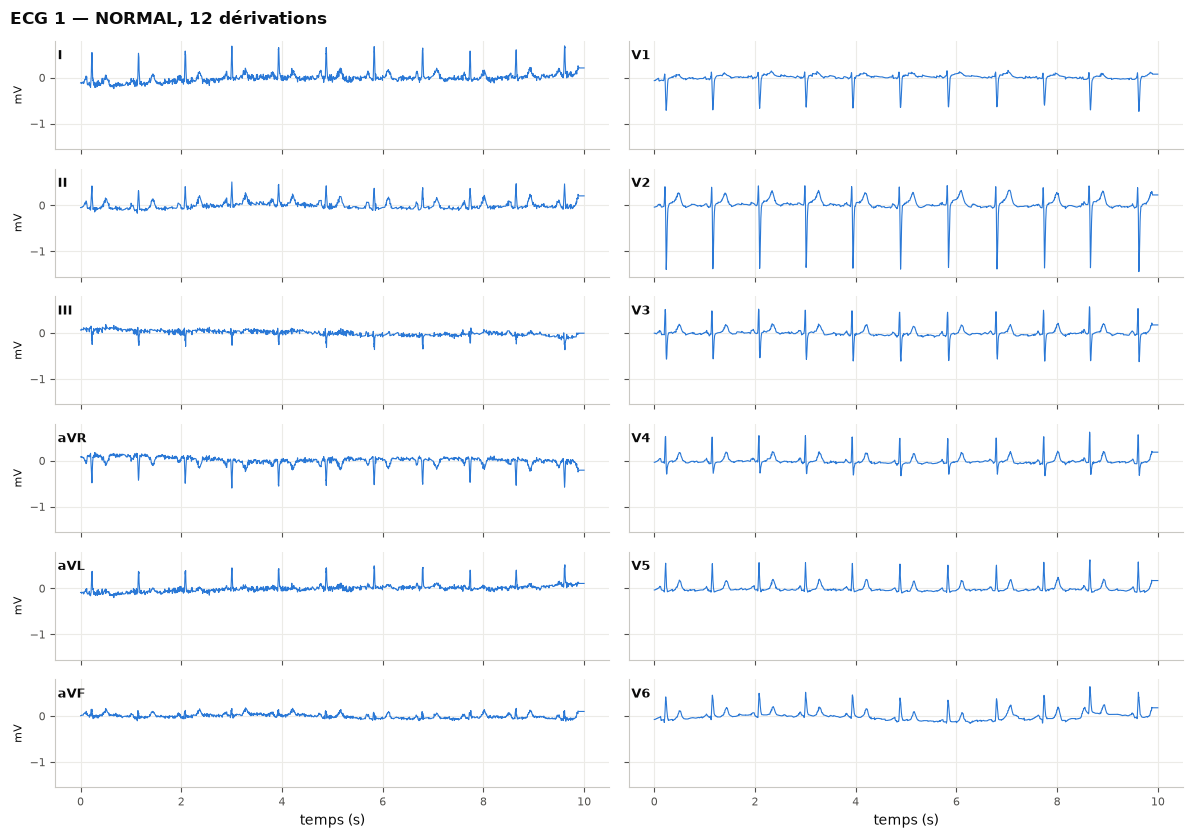

In [10]:
def tracer_12_derivations(signal, titre, couleur):
    """Tracé clinique : dérivations des membres à gauche, précordiales à droite, même échelle en mV."""
    temps = np.arange(N_ECHANTILLONS) / FS
    fig, axes = plt.subplots(6, 2, figsize=(12, 8.5), sharex=True, sharey=True)
    for k, (ax, nom) in enumerate(zip(axes.T.flat, DERIVATIONS)):
        ax.plot(temps, signal[:, k], color=couleur, linewidth=0.8)
        ax.text(0.004, 0.92, nom, transform=ax.transAxes, va="top", fontsize=9, fontweight="bold")
        ax.tick_params(labelsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("temps (s)")
    for ax in axes[:, 0]:
        ax.set_ylabel("mV", fontsize=8)
    fig.suptitle(titre, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


tracer_12_derivations(signal_normal, f"ECG {exemple_normal['ecg_id']} — NORMAL, 12 dérivations", BLEU)

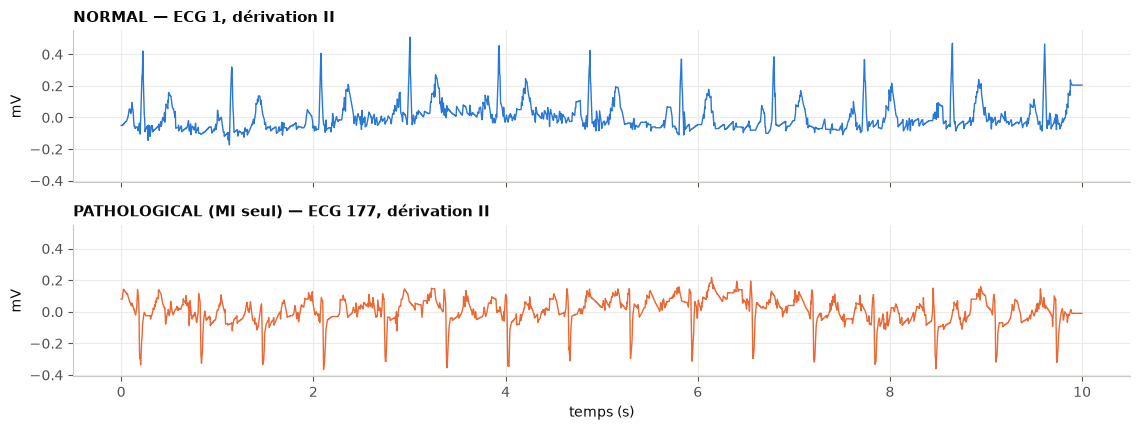

In [11]:
# Même dérivation II pour un ECG normal et un ECG pathologique (infarctus seul).
exemple_mi = selection[(selection["partition"] == "train") & (selection["MI"] == 1)
                       & (selection[SUPERCLASSES].sum(axis=1) == 1)].iloc[0]
temps = np.arange(N_ECHANTILLONS) / FS
fig, axes = plt.subplots(2, 1, figsize=(11.5, 4.4), sharex=True, sharey=True)
for ax, (titre, ligne) in zip(axes, {"NORMAL": exemple_normal, "PATHOLOGICAL (MI seul)": exemple_mi}.items()):
    ax.plot(temps, lire_ecg(DOSSIER_PTBXL / ligne["filename_hr"])[:, DERIVATIONS.index("II")],
            color=COULEUR_CLASSE[titre.split()[0]], linewidth=1)
    ax.set_title(f"{titre} — ECG {ligne['ecg_id']}, dérivation II")
    ax.set_ylabel("mV")
axes[-1].set_xlabel("temps (s)")
fig.tight_layout()
plt.show()

## 3. Extraction des caractéristiques

Un ECG compte 12 × 5 000 = 60 000 valeurs. Le projet le résume par **10 statistiques globales par dérivation**, calculées sur les 10 secondes, soit **120 variables** par ECG :

| Statistique | Définition | Ce qu'elle résume |
|---|---|---|
| `mean` | moyenne des échantillons | niveau moyen du tracé |
| `std` | écart-type | amplitude des variations autour de la moyenne |
| `rms` | $\sqrt{\frac{1}{N}\sum x_t^2}$ | énergie du signal ($\text{rms}^2 = \text{std}^2 + \text{mean}^2$) |
| `median` | médiane | niveau typique, peu sensible aux pics brefs des QRS |
| `iqr` | $Q_3 - Q_1$ | étendue de la moitié centrale des valeurs |
| `min`, `max` | extrêmes | amplitude des déflexions (ondes R, S, Q) |
| `skewness` | asymétrie, estimateur corrigé | déflexions plutôt positives ou plutôt négatives |
| `kurtosis` | aplatissement en excès, estimateur corrigé | tracé « piqué » (pics brefs) ou étalé |
| `line_length` | $\sum_t \lvert x_{t+1} - x_t \rvert$ | longueur de la courbe : fréquence et raideur des variations |

Ces statistiques ignorent l'ordre des battements et ne mesurent ni les ondes ni les intervalles. C'est un choix de simplicité, dont on discutera les limites en conclusion.

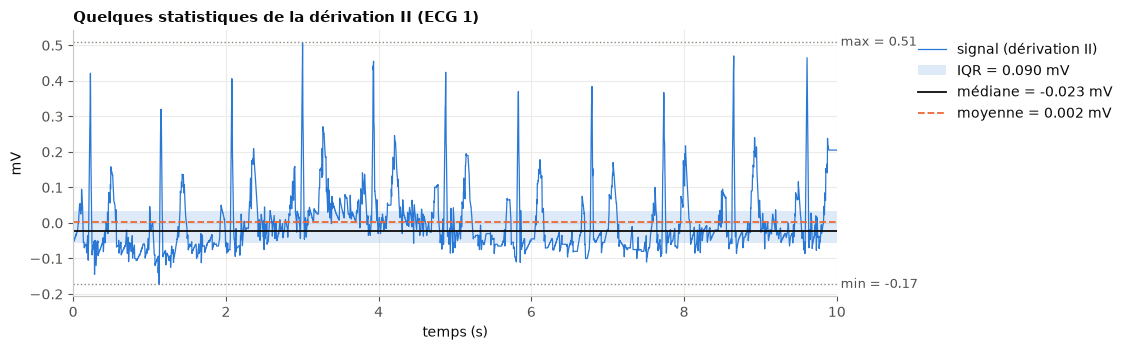

,mean,std,rms,median,iqr,min,max,skewness,kurtosis,line_length
dérivation II,0.0023,0.086,0.086,-0.023,0.09,-0.173,0.508,1.7717,4.0704,38.635


In [12]:
def caracteristiques_derivation(x):
    """Les 10 statistiques d'une dérivation (vecteur de 5 000 valeurs en mV)."""
    q25, q75 = np.percentile(x, [25, 75])
    ecart_type = float(np.std(x, ddof=0))
    constant = ecart_type == 0.0  # asymétrie et kurtosis non définies : mises à 0
    return {
        "mean": float(np.mean(x)),
        "std": ecart_type,
        "rms": float(np.sqrt(np.mean(x ** 2))),
        "median": float(np.median(x)),
        "iqr": float(q75 - q25),
        "min": float(np.min(x)),
        "max": float(np.max(x)),
        "skewness": 0.0 if constant else float(skew(x, bias=False)),
        "kurtosis": 0.0 if constant else float(kurtosis(x, fisher=True, bias=False)),
        "line_length": float(np.sum(np.abs(np.diff(x)))),
    }


def caracteristiques_ecg(signal):
    """Les 120 caractéristiques d'un ECG (5 000 × 12), dans l'ordre de CARACTERISTIQUES."""
    resultat = {}
    for k, derivation in enumerate(DERIVATIONS):
        valeurs = caracteristiques_derivation(signal[:, k])
        # Contrôle d'une identité mathématique : rms² = std² + mean².
        if not np.isclose(valeurs["rms"] ** 2, valeurs["std"] ** 2 + valeurs["mean"] ** 2, rtol=1e-7, atol=1e-10):
            raise ValueError(f"Identité RMS incohérente sur la dérivation {derivation}")
        if not np.isfinite(list(valeurs.values())).all():
            raise ValueError(f"Caractéristique non finie sur la dérivation {derivation}")
        resultat |= {f"{derivation}_{stat}": valeurs[stat] for stat in STATISTIQUES}
    return resultat


# Illustration sur la dérivation II de l'ECG normal du § 2.
x = signal_normal[:, DERIVATIONS.index("II")]
valeurs_II = caracteristiques_derivation(x)
q25, q75 = np.percentile(x, [25, 75])
fig, ax = plt.subplots(figsize=(11.5, 3.6))
ax.plot(temps, x, color=BLEU, linewidth=0.9, label="signal (dérivation II)")
ax.axhspan(q25, q75, color=BLEU, alpha=0.15, linewidth=0, label=f"IQR = {valeurs_II['iqr']:.3f} mV")
ax.axhline(valeurs_II["median"], color=ENCRE, linewidth=1.3, label=f"médiane = {valeurs_II['median']:.3f} mV")
ax.axhline(valeurs_II["mean"], color=ORANGE, linewidth=1.3, linestyle="--", label=f"moyenne = {valeurs_II['mean']:.3f} mV")
for nom in ("min", "max"):
    ax.axhline(valeurs_II[nom], color=GRIS, linewidth=1, linestyle=":")
    ax.text(10.05, valeurs_II[nom], f"{nom} = {valeurs_II[nom]:.2f}", va="center", fontsize=9, color=ENCRE_2)
ax.set_xlim(0, 10)
ax.set_xlabel("temps (s)")
ax.set_ylabel("mV")
ax.set_title(f"Quelques statistiques de la dérivation II (ECG {exemple_normal['ecg_id']})")
ax.legend(loc="upper left", bbox_to_anchor=(1.09, 1))
fig.tight_layout()
plt.show()
pd.Series(valeurs_II, name="dérivation II").round(4).to_frame().T

**Extraction sur tout le sous-échantillon.** Un ECG est lu et résumé en quelques dizaines de millisecondes. Un enregistrement illisible serait écarté et signalé, sans interrompre l'extraction.

In [13]:
lignes, erreurs = [], []
debut = time.perf_counter()
for n, (ecg_id, fichier) in enumerate(zip(selection["ecg_id"], selection["filename_hr"]), 1):
    try:
        lignes.append({"ecg_id": ecg_id, **caracteristiques_ecg(lire_ecg(DOSSIER_PTBXL / fichier))})
    except (OSError, ValueError) as exc:
        erreurs.append({"ecg_id": ecg_id, "erreur": str(exc)})
    if n % 1000 == 0:
        print(f"  {n} / {len(selection)} ECG ({time.perf_counter() - debut:.0f} s)")
caracteristiques = pd.DataFrame(lignes, columns=["ecg_id", *CARACTERISTIQUES])
print(f"{len(caracteristiques)} ECG × {len(CARACTERISTIQUES)} caractéristiques en {time.perf_counter() - debut:.0f} s ; "
      f"ECG écartés : {len(erreurs)}")
if erreurs:
    display(pd.DataFrame(erreurs))

# Une table par partition : métadonnées, superclasses, classe et 120 caractéristiques.
donnees = {p: selection[selection["partition"] == p].merge(caracteristiques, on="ecg_id", validate="one_to_one")
           for p in PARTITIONS}
train, validation, test = donnees["train"], donnees["validation"], donnees["test"]
# Copies modifiables : avec pandas 3, to_numpy() renvoie une vue en lecture seule, que PyTorch signale.
X = {p: d[CARACTERISTIQUES].to_numpy(dtype=np.float64, copy=True) for p, d in donnees.items()}
y = {p: d["label"].to_numpy(copy=True) for p, d in donnees.items()}
for p, d in donnees.items():
    print(f"{p:10} : X {X[p].shape}, {d['label'].mean():.1%} de PATHOLOGICAL")

  1000 / 3000 ECG (26 s)


  2000 / 3000 ECG (51 s)


  3000 / 3000 ECG (80 s)
3000 ECG × 120 caractéristiques en 80 s ; ECG écartés : 0
train      : X (2141, 120), 57.5% de PATHOLOGICAL
validation : X (433, 120), 57.7% de PATHOLOGICAL
test       : X (426, 120), 58.2% de PATHOLOGICAL


## 4. Exploration des données

L'exploration porte sur le **train**, sauf pour la qualité des données et la répartition des classes, contrôlées sur les trois partitions : regarder les variables du test pour orienter les choix de modélisation serait déjà une fuite d'information.

### 4.1 Valeurs manquantes et qualité

In [14]:
pd.DataFrame({
    p: {"ECG": len(d),
        "valeurs manquantes (toutes colonnes utiles)": int(d[["ecg_id", "patient_id", *SUPERCLASSES, *CARACTERISTIQUES]].isna().sum().sum()),
        "valeurs infinies": int(np.isinf(X[p]).sum()),
        "ecg_id en double": int(d["ecg_id"].duplicated().sum()),
        "ECG avec une dérivation plate (écart-type nul)": int((d[[f"{der}_std" for der in DERIVATIONS]] == 0).any(axis=1).sum())}
    for p, d in donnees.items()
}).T

,ECG,valeurs manquantes (toutes colonnes utiles),valeurs infinies,ecg_id en double,ECG avec une dérivation plate (écart-type nul)
train,2141,0,0,0,0
validation,433,0,0,0,0
test,426,0,0,0,0


### 4.2 Répartition des classes

ECG du train co-étiquetés NORM + pathologie (classés PATHOLOGICAL) : 45
ECG pathologiques du train portant plusieurs superclasses         : 496


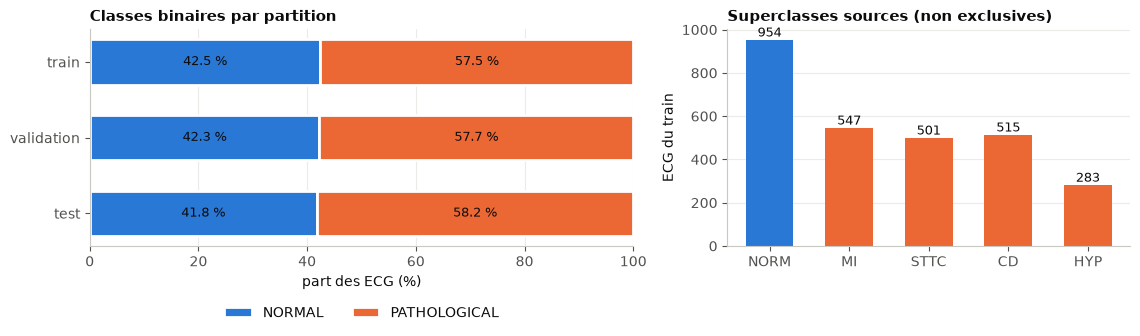

classe,NORMAL,PATHOLOGICAL,total,% PATHOLOGICAL
train,909,1232,2141,57.5
validation,183,250,433,57.7
test,178,248,426,58.2


In [15]:
repartition = pd.DataFrame({p: d["classe"].value_counts() for p, d in donnees.items()}).T[CLASSES]
repartition["total"] = repartition.sum(axis=1)
repartition["% PATHOLOGICAL"] = (100 * repartition["PATHOLOGICAL"] / repartition["total"]).round(1)

# Les superclasses sources ne sont pas exclusives : un ECG peut en porter plusieurs.
nb_pathologies = train[PATHOLOGIES].sum(axis=1)
print(f"ECG du train co-étiquetés NORM + pathologie (classés PATHOLOGICAL) : {int(((train['NORM'] == 1) & (nb_pathologies > 0)).sum())}")
print(f"ECG pathologiques du train portant plusieurs superclasses         : {int((nb_pathologies > 1).sum())}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.35, 1]})
parts = repartition[CLASSES].div(repartition["total"], axis=0) * 100
gauche = np.zeros(len(parts))
for classe in CLASSES:
    ax1.barh(parts.index, parts[classe], left=gauche, height=0.6, color=COULEUR_CLASSE[classe],
             edgecolor="white", linewidth=2, label=classe)
    for i, (debut_barre, largeur) in enumerate(zip(gauche, parts[classe])):
        ax1.text(debut_barre + largeur / 2, i, f"{largeur:.1f} %", ha="center", va="center", fontsize=9)
    gauche += parts[classe].to_numpy()
ax1.invert_yaxis()
ax1.set_xlim(0, 100)
ax1.set_xlabel("part des ECG (%)")
ax1.grid(axis="y", visible=False)
ax1.legend(ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax1.set_title("Classes binaires par partition")

comptes = train[SUPERCLASSES].sum()
ax2.bar(SUPERCLASSES, comptes, width=0.6, color=[BLEU] + [ORANGE] * len(PATHOLOGIES))
for i, valeur in enumerate(comptes):
    ax2.text(i, valeur, f"{valeur:,}".replace(",", " "), ha="center", va="bottom", fontsize=9)
ax2.set_ylabel("ECG du train")
ax2.grid(axis="x", visible=False)
ax2.set_title("Superclasses sources (non exclusives)")
fig.tight_layout()
plt.show()
repartition

### 4.3 Statistiques descriptives et échelles

Le tableau complet compte 120 lignes ; on affiche les 10 statistiques de la dérivation II, puis l'étendue des échelles sur l'ensemble des variables.

In [16]:
display(train[[f"II_{stat}" for stat in STATISTIQUES]].describe().T.round(4))

ecarts_types = train[CARACTERISTIQUES].std().sort_values()
print(f"Écart-type le plus faible : {ecarts_types.index[0]:15} {ecarts_types.iloc[0]:.4g}")
print(f"Écart-type le plus élevé  : {ecarts_types.index[-1]:15} {ecarts_types.iloc[-1]:.4g}")
print(f"Rapport entre les deux    : {ecarts_types.iloc[-1] / ecarts_types.iloc[0]:,.0f}".replace(",", " "))

,count,mean,std,min,25%,50%,75%,max
II_mean,2141.0,-0.0022,0.0390,-1.2574,-0.0037,-0.0012,0.0015,0.5255
II_std,2141.0,0.1466,0.0622,0.0361,0.1050,0.1332,0.1755,0.5335
II_rms,2141.0,0.1479,0.0709,0.0362,0.1052,0.1334,0.1756,1.3148
II_median,2141.0,-0.0234,0.0464,-1.3320,-0.0380,-0.0250,-0.0100,0.5200
II_iqr,2141.0,0.1140,0.0684,0.0280,0.0750,0.0980,0.1340,0.8850
II_min,2141.0,-0.3784,0.2496,-2.0580,-0.4490,-0.3050,-0.2200,0.1200
II_max,2141.0,0.8378,0.4078,0.0970,0.5500,0.7830,1.0640,3.2560
II_skewness,2141.0,1.9620,1.8846,-4.5436,0.7299,2.2776,3.4033,6.0502
II_kurtosis,2141.0,11.0046,7.9551,-1.0583,4.5372,9.6737,16.1468,62.9912
II_line_length,2141.0,43.1681,21.3885,10.7720,29.8600,38.8860,51.1120,233.3630


Écart-type le plus faible : V4_mean         0.0235
Écart-type le plus élevé  : V2_line_length  28.18
Rapport entre les deux    : 1 199


### 4.4 Quelles variables séparent les classes ?

Pour chaque variable prise seule, on calcule sur le train son AUROC : la probabilité qu'un ECG pathologique tiré au hasard ait une valeur plus grande qu'un ECG normal tiré au hasard. On l'oriente, max(AUROC, 1 − AUROC), pour que 0,5 signifie « aucun pouvoir séparateur » quel que soit le sens de l'effet.

In [17]:
auroc_univariee = pd.Series({c: roc_auc_score(y["train"], train[c]) for c in CARACTERISTIQUES})
pouvoir = (auroc_univariee - 0.5).abs() + 0.5
classement = (pd.DataFrame({"AUROC univariée": auroc_univariee, "AUROC orientée": pouvoir,
                            "plus élevée chez": np.where(auroc_univariee > 0.5, "PATHOLOGICAL", "NORMAL")})
              .sort_values("AUROC orientée", ascending=False))
print(f"Variables avec AUROC orientée ≥ 0,65 : {(pouvoir >= 0.65).sum()} sur {len(pouvoir)} ; "
      f"meilleure : {classement.index[0]} ({classement['AUROC orientée'].iloc[0]:.3f})")
classement.head(10).round(4)

Variables avec AUROC orientée ≥ 0,65 : 15 sur 120 ; meilleure : II_median (0.705)


,AUROC univariée,AUROC orientée,plus élevée chez
II_median,0.7052,0.7052,PATHOLOGICAL
III_min,0.2983,0.7017,NORMAL
aVL_std,0.6864,0.6864,PATHOLOGICAL
aVL_rms,0.6857,0.6857,PATHOLOGICAL
aVF_median,0.6827,0.6827,PATHOLOGICAL
aVR_median,0.3177,0.6823,NORMAL
aVF_skewness,0.3234,0.6766,NORMAL
aVF_min,0.3243,0.6757,NORMAL
aVL_max,0.6698,0.6698,PATHOLOGICAL
V3_median,0.6691,0.6691,PATHOLOGICAL


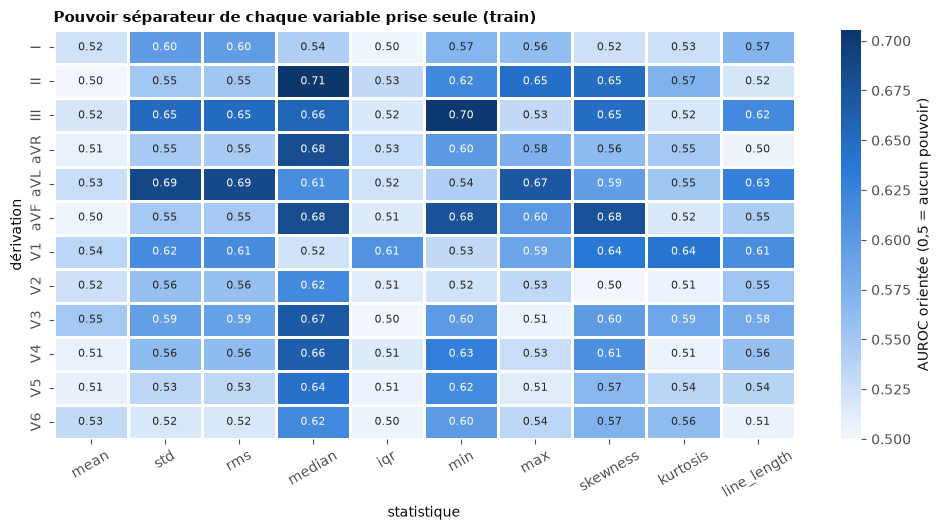

In [18]:
carte = pd.DataFrame(pouvoir[CARACTERISTIQUES].to_numpy().reshape(len(DERIVATIONS), len(STATISTIQUES)),
                     index=DERIVATIONS, columns=STATISTIQUES)
fig, ax = plt.subplots(figsize=(10, 5.4))
sns.heatmap(carte, annot=True, fmt=".2f", annot_kws={"fontsize": 8}, cmap=SEQUENTIEL,
            vmin=0.5, vmax=float(carte.to_numpy().max()), linewidths=1, linecolor="white",
            cbar_kws={"label": "AUROC orientée (0,5 = aucun pouvoir)"}, ax=ax)
ax.set_xlabel("statistique")
ax.set_ylabel("dérivation")
ax.set_title("Pouvoir séparateur de chaque variable prise seule (train)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

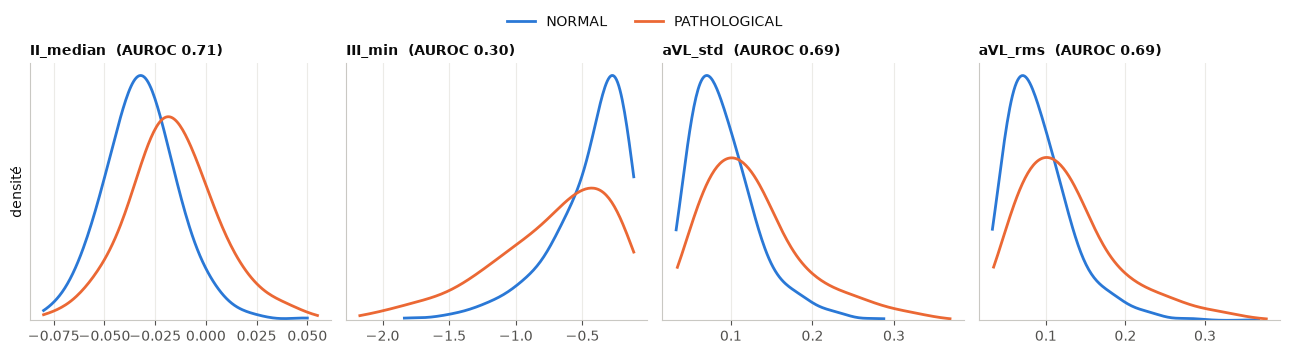

In [19]:
# Densités par classe des quatre variables les plus séparatrices. Une estimation lissée évite
# l'effet de peigne dû à la quantification du signal (pas de 1 µV) ; 1 % des valeurs extrêmes
# de chaque côté est masqué pour la lisibilité.
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, colonne in zip(axes, classement.index[:4]):
    bas, haut = train[colonne].quantile([0.01, 0.99])
    for classe in CLASSES:
        valeurs = train.loc[train["classe"] == classe, colonne]
        sns.kdeplot(valeurs[valeurs.between(bas, haut)], bw_adjust=1.5, cut=0, linewidth=2,
                    color=COULEUR_CLASSE[classe], label=classe, ax=ax)
    ax.set_title(f"{colonne}  (AUROC {classement.loc[colonne, 'AUROC univariée']:.2f})", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([])
axes[0].set_ylabel("densité")
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, ncols=2, loc="upper center", bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
plt.show()

### 4.5 Redondance entre variables

Paires de variables avec |r| > 0,95 : 39 sur 7140
Paires de variables avec |r| > 0,80 : 165 sur 7140


,,|r|
V4_std,V4_rms,0.9943
V2_std,V2_rms,0.9920
V3_std,V3_rms,0.9905
V1_std,V1_rms,0.9893
aVL_std,aVL_rms,0.9874
I_std,I_rms,0.9859


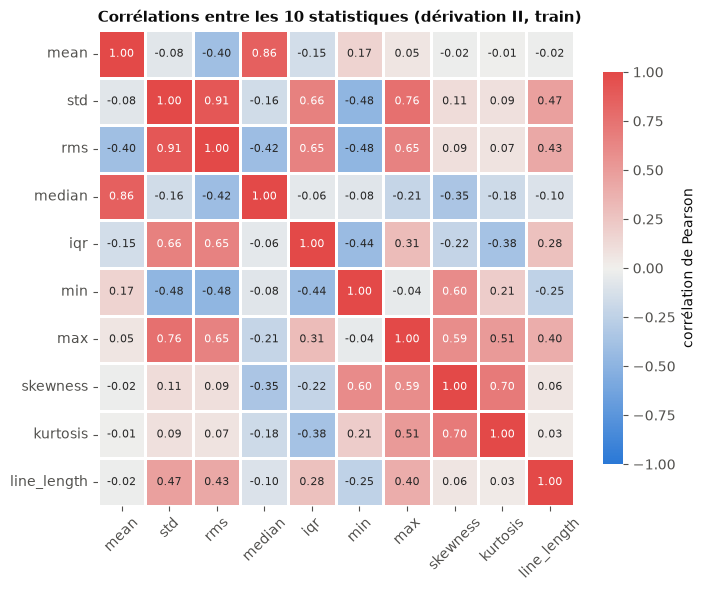

In [20]:
correlations = train[CARACTERISTIQUES].corr()
# dropna : depuis pandas 3, stack() conserve les valeurs masquées (triangle inférieur).
paires = correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1)).stack().dropna()
print(f"Paires de variables avec |r| > 0,95 : {(paires.abs() > 0.95).sum()} sur {len(paires)}")
print(f"Paires de variables avec |r| > 0,80 : {(paires.abs() > 0.80).sum()} sur {len(paires)}")
display(paires.abs().sort_values(ascending=False).head(6).round(4).rename("|r|").to_frame())

colonnes_II = [f"II_{stat}" for stat in STATISTIQUES]
fig, ax = plt.subplots(figsize=(7.2, 6))
sns.heatmap(train[colonnes_II].corr(), annot=True, fmt=".2f", annot_kws={"fontsize": 8},
            cmap=DIVERGENT, vmin=-1, vmax=1, square=True, linewidths=1, linecolor="white",
            xticklabels=STATISTIQUES, yticklabels=STATISTIQUES,
            cbar_kws={"label": "corrélation de Pearson", "shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre les 10 statistiques (dérivation II, train)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

### Ce que l'exploration implique pour la suite

| Constat | Conséquence |
|---|---|
| Aucune valeur manquante, infinie ou dupliquée, aucune dérivation plate dans le sous-échantillon. | L'imputation n'a pas d'effet ici ; elle reste dans le pipeline par robustesse (§ 5). |
| Les écarts-types vont de 0,02 (`V4_mean`) à 28 (`V2_line_length`), soit un rapport de 1 200 ; il atteint 32 000 sur la base complète, qui contient quelques valeurs extrêmes. | Centrage-réduction indispensable : sans lui, les variables de grande échelle domineraient la descente de gradient du MLP. |
| 57,5 à 58,2 % d'ECG pathologiques selon la partition. | Répondre toujours `PATHOLOGICAL` donne déjà 58 % d'exactitude : on suit plutôt l'AUROC, le F1 macro et les rappels par classe, et on règle le seuil de décision. |
| Superclasses non exclusives : 496 ECG pathologiques du train portent plusieurs superclasses, 45 sont co-étiquetés NORM et pathologie. | La règle binaire doit trancher ces cas : priorité à la pathologie (§ 1.3). |
| Aucune variable seule ne dépasse 0,71 d'AUROC ; 15 sur 120 atteignent 0,65. | L'information est répartie sur de nombreuses variables : il faut un modèle qui les combine. |
| Les médianes (II, aVF, aVR, V3), les minimums des dérivations inférieures (III, aVF) et l'amplitude en aVL sont les plus informatifs ; les moyennes ne le sont presque pas. | Hypothèse : la médiane résume le niveau du tracé hors des complexes QRS, là où se lisent les décalages du segment ST. |
| Écart-type et RMS sont presque confondus (r jusqu'à 0,994, la moyenne étant proche de 0) ; 39 paires de variables ont \|r\| > 0,95. | Redondance sans gêne pour la prédiction (régularisation, dropout), mais qui interdit de lire un poids isolé comme l'importance d'une variable. Aucune sélection de variables n'est faite. |

## 5. Prétraitement dans un `Pipeline`

- **Encodage.** Seule la cible est encodée (§ 1.3) ; aucune variable d'entrée n'est catégorielle.
- **Imputation.** Il n'y a aucune valeur manquante (§ 4.1). Une imputation par la médiane est tout de même placée en tête du pipeline : sans effet sur ces données, elle protège le modèle si une statistique venait à manquer.
- **Normalisation.** Centrage-réduction, car les échelles diffèrent de plusieurs ordres de grandeur (§ 4.3) : sans elle, les variables de grande échelle domineraient la descente de gradient.

Le pipeline est ajusté **sur le train uniquement**, puis appliqué tel quel à la validation et au test. Dans la validation croisée (§ 6.5), il est réajusté dans chaque pli.

In [21]:
def pretraitement():
    """Imputation par la médiane puis centrage-réduction, à ajuster sur les seules données d'entraînement."""
    return Pipeline([("imputation", SimpleImputer(strategy="median")),
                     ("standardisation", StandardScaler())])


prep = pretraitement().fit(X["train"])
Z = {p: prep.transform(X[p]) for p in PARTITIONS}

# Le train est exactement centré-réduit ; validation et test seulement approximativement,
# preuve que leurs propres statistiques n'ont pas servi.
pd.DataFrame({p: {"|moyenne| maximale": np.abs(Z[p].mean(axis=0)).max(),
                  "écart-type minimal": Z[p].std(axis=0).min(),
                  "écart-type maximal": Z[p].std(axis=0).max()}
              for p in PARTITIONS}).T.round(4)

,|moyenne| maximale,écart-type minimal,écart-type maximal
train,0.0000,1.0000,1.0000
validation,0.3298,0.0386,5.4365
test,0.1402,0.0361,1.4027


## 6. Modèle et entraînement

### 6.1 Perceptron multicouche

120 entrées → 128 neurones → 64 neurones → 2 sorties. Chaque couche cachée applique une transformation affine, une activation ReLU puis un dropout de 0,3 (pendant l'apprentissage, 30 % des neurones sont éteints au hasard, ce qui limite le surapprentissage). La couche de sortie produit deux logits, transformés en probabilités par softmax. La perte est l'entropie croisée, optimisée par AdamW (taux d'apprentissage 10⁻³, *weight decay* 10⁻⁴) sur des mini-lots de 128 ECG.

In [22]:
class MLP(nn.Module):
    """Couches cachées entièrement connectées (ReLU puis dropout), puis une couche linéaire de logits."""

    def __init__(self, n_entrees, couches_cachees, n_sorties, dropout):
        super().__init__()
        couches, taille = [], n_entrees
        for n_neurones in couches_cachees:
            couches += [nn.Linear(taille, n_neurones), nn.ReLU(), nn.Dropout(dropout)]
            taille = n_neurones
        couches.append(nn.Linear(taille, n_sorties))
        self.reseau = nn.Sequential(*couches)

    def forward(self, x):
        return self.reseau(x)


def creer_mlp(config):
    return MLP(len(CARACTERISTIQUES), config["hidden_sizes"], len(CLASSES), config["dropout"])


def nombre_parametres(modele):
    return sum(parametre.numel() for parametre in modele.parameters())


def nom_architecture(couches):
    return "120–" + "–".join(map(str, couches)) + "–2"


print(creer_mlp(CONFIG))
print(f"{nombre_parametres(creer_mlp(CONFIG)):,} paramètres entraînables".replace(",", " "))

MLP(
  (reseau): Sequential(
    (0): Linear(in_features=120, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)
23 874 paramètres entraînables


### 6.2 Procédure d'entraînement

- **Arrêt précoce.** Après chaque époque, on mesure l'AUROC sur la validation ; on conserve les poids de la meilleure époque et on s'arrête après 20 époques sans amélioration (au plus 200).
- **Seuil de décision.** Le réseau donne une probabilité `PATHOLOGICAL`. Plutôt que le seuil arbitraire de 0,5, on retient celui qui maximise le F1 de la classe `PATHOLOGICAL` sur la validation, parmi 0,01, 0,02, …, 0,99.
- **Reproductibilité.** Une graine fixe les poids initiaux, l'ordre des mini-lots et le dropout ; les opérations de PyTorch sont rendues déterministes.

In [23]:
def fixer_graines(graine):
    """Rend un entraînement reproductible : mêmes poids initiaux, mêmes mini-lots, même dropout."""
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)
    torch.use_deterministic_algorithms(True)
    torch.set_num_threads(CONFIG["num_threads"])


def probabilites(modele, X):
    """Probabilités softmax (n × 2), en mode évaluation (dropout désactivé)."""
    modele.eval()
    with torch.no_grad():
        return torch.softmax(modele(torch.as_tensor(X, dtype=torch.float32)), dim=1).numpy()


def preparer(config, graine, X_train, y_train):
    """Modèle initialisé, perte, optimiseur et mini-lots mélangés, pour une graine donnée."""
    fixer_graines(graine)
    X_t = torch.as_tensor(X_train, dtype=torch.float32)
    y_t = torch.as_tensor(y_train, dtype=torch.long)
    modele = creer_mlp(config)
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=config["learning_rate"],
                                   weight_decay=config["weight_decay"])
    lots = DataLoader(TensorDataset(X_t, y_t), batch_size=config["batch_size"], shuffle=True,
                      generator=torch.Generator().manual_seed(graine))
    return modele, nn.CrossEntropyLoss(), optimiseur, lots, X_t, y_t


def une_epoque(modele, perte, optimiseur, lots):
    """Une passe sur les mini-lots : propagation, rétropropagation, mise à jour des poids."""
    modele.train()
    for lot_x, lot_y in lots:
        optimiseur.zero_grad()
        perte(modele(lot_x), lot_y).backward()
        optimiseur.step()


def entrainer_mlp(config, graine, X_train, y_train, X_val, y_val):
    """Entraîne un MLP avec arrêt précoce sur l'AUROC de validation.

    Retourne le modèle à sa meilleure époque, ses probabilités sur la validation,
    cette époque et l'historique des mesures de chaque époque.
    """
    modele, perte, optimiseur, lots, X_t, y_t = preparer(config, graine, X_train, y_train)
    X_v, y_v = torch.as_tensor(X_val, dtype=torch.float32), torch.as_tensor(y_val, dtype=torch.long)
    meilleure_auroc, meilleure_epoque, meilleur_etat, sans_progres, historique = -np.inf, 0, None, 0, []
    for epoque in range(1, config["max_epochs"] + 1):
        une_epoque(modele, perte, optimiseur, lots)
        p_val, p_train = probabilites(modele, X_v), probabilites(modele, X_t)
        with torch.no_grad():
            mesure = {"epoch": epoque,
                      "train_loss": float(perte(modele(X_t), y_t)), "val_loss": float(perte(modele(X_v), y_v)),
                      "train_accuracy": float(np.mean(p_train.argmax(axis=1) == y_train)),
                      "val_accuracy": float(np.mean(p_val.argmax(axis=1) == y_val)),
                      "val_auroc": float(roc_auc_score(y_val, p_val[:, 1]))}
        historique.append(mesure)
        if mesure["val_auroc"] > meilleure_auroc:
            meilleure_auroc, meilleure_epoque, sans_progres = mesure["val_auroc"], epoque, 0
            meilleur_etat = deepcopy(modele.state_dict())
        else:
            sans_progres += 1
            if sans_progres >= config["patience"]:
                break
    modele.load_state_dict(meilleur_etat)
    return modele, probabilites(modele, X_v)[:, 1], meilleure_epoque, pd.DataFrame(historique)


def entrainer_epoques_fixes(config, graine, X_train, y_train, n_epoques):
    """Entraîne un MLP pendant un nombre d'époques fixé à l'avance (validation croisée, § 6.5)."""
    modele, perte, optimiseur, lots, _, _ = preparer(config, graine, X_train, y_train)
    for _ in range(n_epoques):
        une_epoque(modele, perte, optimiseur, lots)
    return modele


def choisir_seuil(y_val, p_val):
    """Seuil de la grille 0,01…0,99 qui maximise le F1 de la classe PATHOLOGICAL sur la validation."""
    f1s = [f1_score(y_val, p_val >= seuil, zero_division=0) for seuil in SEUILS]
    return float(SEUILS[int(np.argmax(f1s))])


def mesures(y_vrai, p_patho, seuil):
    """Mesures rapportées pour une probabilité PATHOLOGICAL et un seuil donnés."""
    predit = (p_patho >= seuil).astype(np.int64)
    return {"AUROC": roc_auc_score(y_vrai, p_patho),
            "AP PATHO": average_precision_score(y_vrai, p_patho),
            "exactitude": accuracy_score(y_vrai, predit),
            "F1 macro": f1_score(y_vrai, predit, average="macro", zero_division=0),
            "précision PATHO": precision_score(y_vrai, predit, zero_division=0),
            "rappel PATHO": recall_score(y_vrai, predit, zero_division=0),
            "rappel NORMAL": recall_score(y_vrai, predit, pos_label=0, zero_division=0)}

### 6.3 Réglage des hyperparamètres : architecture et dropout

La grille croise **4 architectures × 3 taux de dropout**, avec deux graines chacune, évaluées sur la validation. Elle sert d'**analyse de sensibilité** : vérifier qu'aucune configuration ne fait nettement mieux que celle du projet, et voir quels hyperparamètres comptent. Le test n'intervient pas.

In [24]:
GRILLE = [{"hidden_sizes": couches, "dropout": dropout}
          for couches in ([64], [128], [128, 64], [256, 128]) for dropout in (0.0, 0.3, 0.5)]
GRAINES_GRILLE = (0, 1)

lignes, debut = [], time.perf_counter()
for variante in GRILLE:
    config = {**CONFIG, **variante}
    for graine in GRAINES_GRILLE:
        _, p_val, epoque, _ = entrainer_mlp(config, graine, Z["train"], y["train"], Z["validation"], y["validation"])
        lignes.append({"architecture": nom_architecture(variante["hidden_sizes"]), "dropout": variante["dropout"],
                       "paramètres": nombre_parametres(creer_mlp(config)), "graine": graine,
                       "AUROC validation": roc_auc_score(y["validation"], p_val), "meilleure époque": epoque})
grille = pd.DataFrame(lignes)
print(f"{len(grille)} entraînements en {time.perf_counter() - debut:.0f} s")

synthese_grille = (grille.groupby(["architecture", "dropout"])
                   .agg(**{"paramètres": ("paramètres", "first"),
                           "AUROC moyenne": ("AUROC validation", "mean"),
                           "écart entre graines": ("AUROC validation", lambda s: s.max() - s.min()),
                           "époque moyenne": ("meilleure époque", "mean")})
                   .sort_values("AUROC moyenne", ascending=False))
PROJET = (nom_architecture(CONFIG["hidden_sizes"]), CONFIG["dropout"])
meilleure = synthese_grille.index[0]
print(f"Meilleure configuration : {meilleure[0]}, dropout {meilleure[1]} ; avance sur celle du projet : "
      f"{synthese_grille.loc[meilleure, 'AUROC moyenne'] - synthese_grille.loc[PROJET, 'AUROC moyenne']:+.4f}")
print(f"Rang de la configuration du projet ({PROJET[0]}, dropout {PROJET[1]}) : "
      f"{list(synthese_grille.index).index(PROJET) + 1} sur {len(synthese_grille)}")
synthese_grille.round(4)

24 entraînements en 71 s
Meilleure configuration : 120–64–2, dropout 0.5 ; avance sur celle du projet : +0.0047
Rang de la configuration du projet (120–128–64–2, dropout 0.3) : 6 sur 12


paramètres  AUROC moyenne  écart entre graines  \
architecture  dropout                                                   
120–64–2      0.5            7874         0.8861               0.0021   
120–128–64–2  0.5           23874         0.8856               0.0055   
120–128–2     0.5           15746         0.8843               0.0018   
120–256–128–2 0.5           64130         0.8835               0.0057   
120–64–2      0.3            7874         0.8824               0.0132   
120–128–64–2  0.3           23874         0.8814               0.0059   
120–128–2     0.3           15746         0.8799               0.0104   
              0.0           15746         0.8792               0.0058   
120–256–128–2 0.3           64130         0.8772               0.0110   
              0.0           64130         0.8764               0.0066   
120–64–2      0.0            7874         0.8760               0.0107   
120–128–64–2  0.0           23874         0.8749               0.0050   

                       époque moyenne  
architecture  dropout                  
120–64–2      0.5                48.5  
120–128–64–2  0.5                41.0  
120–128–2     0.5                39.5  
120–256–128–2 0.5                26.5  
120–64–2      0.3                45.0  
120–128–64–2  0.3                27.0  
120–128–2     0.3                22.5  
              0.0                18.0  
120–256–128–2 0.3                14.0  
              0.0                 7.0  
120–64–2      0.0                22.0  
120–128–64–2  0.0                13.5

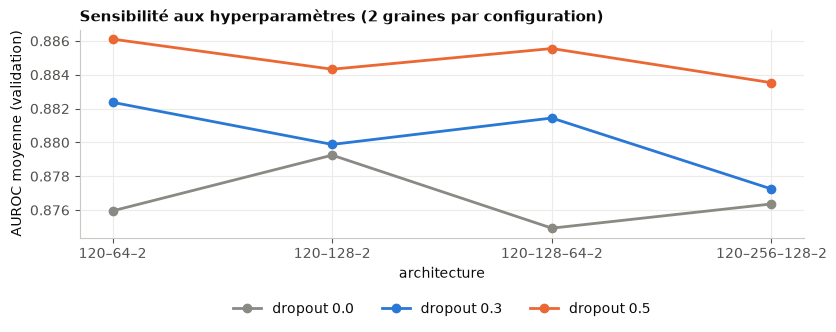

In [25]:
# AUROC moyenne de validation selon l'architecture et le dropout.
pivot = synthese_grille["AUROC moyenne"].unstack("dropout").reindex(
    [nom_architecture(c) for c in ([64], [128], [128, 64], [256, 128])])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for dropout, couleur in zip(pivot.columns, (GRIS, BLEU, ORANGE)):
    ax.plot(pivot.index, pivot[dropout], marker="o", color=couleur, label=f"dropout {dropout}")
ax.set_ylabel("AUROC moyenne (validation)")
ax.set_xlabel("architecture")
ax.set_title("Sensibilité aux hyperparamètres (2 graines par configuration)")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
fig.tight_layout()
plt.show()

**Lecture de la grille.**

- **Le dropout compte plus que l'architecture.** Pour chacune des quatre architectures, l'AUROC croît avec le dropout : de 0,875–0,879 sans dropout à 0,884–0,886 avec un dropout de 0,5. Sans dropout, les réseaux atteignent leur meilleure époque très tôt (7 à 22 époques en moyenne) : ils surapprennent vite.
- **Sur ce sous-échantillon, une régularisation plus forte aide.** La meilleure configuration (120–64–2, dropout 0,5) devance celle du projet de 0,005. C'est attendu : avec cinq fois moins d'ECG d'entraînement, le risque de surapprentissage augmente. Sur la base complète, la même grille ne faisait apparaître aucune configuration nettement meilleure (avance de 0,0035 pour la meilleure, inférieure à la variabilité entre graines).
- **Configuration conservée : 120–128–64–2, dropout 0,3**, celle du projet. L'avance de 0,005 est du même ordre que l'écart entre deux graines d'une même configuration (jusqu'à 0,013 ici, 0,006 entre les cinq graines finales du § 6.4) : avec deux graines, la grille ne départage pas sûrement ces configurations. On garde donc le réseau du projet, ce qui rend ce notebook directement comparable à l'entraînement sur la base complète (§ 10).

### 6.4 Entraînement final sur cinq graines et choix du seuil

Pour chaque graine : apprentissage sur le train avec arrêt précoce sur la validation, puis choix du seuil sur la validation. Cinq graines permettent de mesurer la variabilité due à l'initialisation et à l'ordre des mini-lots.

In [26]:
CONFIG_FINALE = dict(CONFIG)
finaux, debut = {}, time.perf_counter()
for graine in GRAINES:
    modele, p_val, epoque, historique = entrainer_mlp(
        CONFIG_FINALE, graine, Z["train"], y["train"], Z["validation"], y["validation"])
    finaux[graine] = {"modele": modele, "p_val": p_val, "epoque": epoque, "historique": historique,
                      "seuil": choisir_seuil(y["validation"], p_val)}
print(f"{len(GRAINES)} modèles entraînés en {time.perf_counter() - debut:.0f} s")

pd.DataFrame({g: {"meilleure époque": f["epoque"], "époques exécutées": len(f["historique"]),
                  "AUROC validation": round(roc_auc_score(y["validation"], f["p_val"]), 4),
                  "seuil retenu": f["seuil"],
                  "F1 PATHO validation": round(f1_score(y["validation"], f["p_val"] >= f["seuil"]), 4)}
              for g, f in finaux.items()}).T.rename_axis("graine")

5 modèles entraînés en 19 s


,meilleure époque,époques exécutées,AUROC validation,seuil retenu,F1 PATHO validation
graine,,,,,
0,32.0,52.0,0.8785,0.40,0.8402
1,22.0,42.0,0.8844,0.31,0.8421
2,32.0,52.0,0.8818,0.35,0.8454
3,26.0,46.0,0.8787,0.26,0.8435
4,17.0,37.0,0.8811,0.35,0.8376


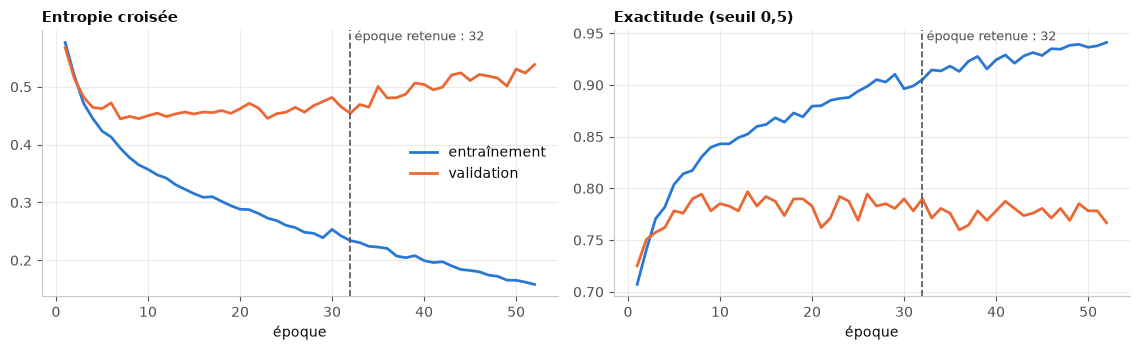

In [27]:
# Courbes d'apprentissage de la graine 0 : l'arrêt précoce conserve l'époque marquée.
historique, epoque0 = finaux[0]["historique"], finaux[0]["epoque"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.6))
for ax, mesure, titre in ((ax1, "loss", "Entropie croisée"), (ax2, "accuracy", "Exactitude (seuil 0,5)")):
    ax.plot(historique["epoch"], historique[f"train_{mesure}"], color=BLEU, label="entraînement")
    ax.plot(historique["epoch"], historique[f"val_{mesure}"], color=ORANGE, label="validation")
    ax.axvline(epoque0, color=ENCRE_2, linestyle="--", linewidth=1.2)
    ax.text(epoque0, ax.get_ylim()[1], f" époque retenue : {epoque0}", va="top", fontsize=9, color=ENCRE_2)
    ax.set_xlabel("époque")
    ax.set_title(titre)
ax1.legend(loc="center right")
fig.tight_layout()
plt.show()

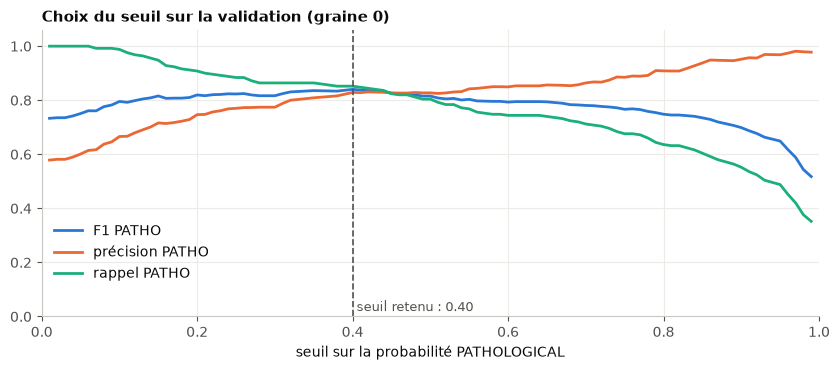

In [28]:
# Effet du seuil sur la validation (graine 0).
p_val0, seuil0 = finaux[0]["p_val"], finaux[0]["seuil"]
courbes_seuil = {
    "F1 PATHO": [f1_score(y["validation"], p_val0 >= s, zero_division=0) for s in SEUILS],
    "précision PATHO": [precision_score(y["validation"], p_val0 >= s, zero_division=0) for s in SEUILS],
    "rappel PATHO": [recall_score(y["validation"], p_val0 >= s, zero_division=0) for s in SEUILS],
}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for (nom, valeurs), couleur in zip(courbes_seuil.items(), (BLEU, ORANGE, AQUA)):
    ax.plot(SEUILS, valeurs, color=couleur, label=nom)
ax.axvline(seuil0, color=ENCRE_2, linestyle="--", linewidth=1.2)
ax.text(seuil0, 0.02, f" seuil retenu : {seuil0:.2f}", fontsize=9, color=ENCRE_2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.06)
ax.set_xlabel("seuil sur la probabilité PATHOLOGICAL")
ax.set_title("Choix du seuil sur la validation (graine 0)")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.08))
fig.tight_layout()
plt.show()

**Lecture.**

- **Courbes d'apprentissage.** La perte d'entraînement décroît régulièrement, tandis que la perte de validation cesse de baisser vers la dixième époque puis remonte : le réseau devient trop confiant. L'AUROC de validation, qui ne juge que l'ordre des scores, progresse pourtant jusqu'à l'époque 32. C'est elle que surveille l'arrêt précoce, car la qualité du classement est ce qui compte ici, le seuil étant réglé ensuite. L'écart croissant entre l'exactitude d'entraînement (0,90 à l'époque retenue) et celle de validation (0,78) traduit le surapprentissage que l'arrêt précoce contient.
- **Choix du seuil.** Abaisser le seuil augmente le rappel `PATHOLOGICAL` et diminue la précision ; le F1 culmine sur un plateau assez plat. Le seuil retenu varie de 0,26 à 0,40 selon la graine, car sur 433 ECG de validation, quelques cas suffisent à déplacer le maximum. Tous ces seuils sont inférieurs à 0,5 : maximiser le F1 de la classe pathologique, majoritaire, pousse à la signaler largement.

### 6.5 Estimation par validation croisée imbriquée

La validation n'est qu'un fold : pour estimer la performance plus solidement, sans toucher au test, on répète **tout le réglage** à l'intérieur de chaque pli d'une validation croisée sur les folds 1 à 5 du train :

1. le fold `k` est tenu à l'écart pour l'évaluation ;
2. parmi les quatre autres, le fold suivant (de façon cyclique) sert de validation interne : il fixe l'époque d'arrêt et le seuil ;
3. le prétraitement est réajusté, puis le réseau réentraîné sur les quatre folds pendant le nombre d'époques retenu ;
4. le modèle est évalué sur le fold `k`.

Les folds étant disjoints par patient, aucun patient n'est partagé entre entraînement et évaluation. On répète l'opération pour les cinq graines.

In [29]:
def pli_croise(config, graine, pli, X, y, patients, folds):
    """Un pli externe de la validation croisée imbriquée ; renvoie les mesures sur le fold tenu à l'écart."""
    externe_train, externe_test = np.flatnonzero(folds != pli), np.flatnonzero(folds == pli)
    autres = sorted(set(PARTITIONS["train"]) - {pli})
    pli_interne = autres[(pli - 1) % len(autres)]
    interne_train = externe_train[folds[externe_train] != pli_interne]
    interne_val = externe_train[folds[externe_train] == pli_interne]
    for a, b in ((interne_train, interne_val), (externe_train, externe_test)):
        if np.intersect1d(patients[a], patients[b]).size:
            raise ValueError(f"Fuite de patients dans le pli {pli}.")

    graine_pli = graine + 1009 * pli
    # Réglage interne : époque d'arrêt et seuil choisis sans voir le fold évalué.
    prep_interne = pretraitement().fit(X[interne_train])
    _, p_val, epoque, _ = entrainer_mlp(config, graine_pli, prep_interne.transform(X[interne_train]), y[interne_train],
                                        prep_interne.transform(X[interne_val]), y[interne_val])
    seuil = choisir_seuil(y[interne_val], p_val)
    # Réentraînement sur les quatre folds, puis évaluation du fold tenu à l'écart.
    prep_externe = pretraitement().fit(X[externe_train])
    modele = entrainer_epoques_fixes(config, graine_pli, prep_externe.transform(X[externe_train]),
                                     y[externe_train], epoque)
    p_test = probabilites(modele, prep_externe.transform(X[externe_test]))[:, 1]
    return {"graine": graine, "fold évalué": pli, "validation interne": pli_interne,
            "époque retenue": epoque, "seuil retenu": seuil, **mesures(y[externe_test], p_test, seuil)}


folds_train = train["strat_fold"].to_numpy(dtype=np.int64)
patients_train = train["patient_id"].to_numpy(dtype=np.int64)
debut = time.perf_counter()
validation_croisee = pd.DataFrame([pli_croise(CONFIG_FINALE, graine, pli, X["train"], y["train"], patients_train, folds_train)
                                   for graine in GRAINES for pli in PARTITIONS["train"]])
print(f"{len(validation_croisee)} plis (5 graines × 5 folds) en {time.perf_counter() - debut:.0f} s")
print("Moyenne ± écart-type sur les 25 plis : "
      + " ; ".join(f"{m} {moyenne_ecart(validation_croisee[m])}" for m in ("AUROC", "AP PATHO", "F1 macro")))
par_fold = (validation_croisee.groupby("fold évalué")
            .agg(**{"validation interne": ("validation interne", "first"),
                    "AUROC (moy. 5 graines)": ("AUROC", "mean"), "F1 macro (moy.)": ("F1 macro", "mean"),
                    "seuil min": ("seuil retenu", "min"), "seuil max": ("seuil retenu", "max")}))
par_fold.insert(1, "ECG évalués", pd.Series(folds_train).value_counts())
par_fold.round(4)

25 plis (5 graines × 5 folds) en 110 s
Moyenne ± écart-type sur les 25 plis : AUROC 0.8676 ± 0.0114 ; AP PATHO 0.8960 ± 0.0228 ; F1 macro 0.7740 ± 0.0204


,validation interne,ECG évalués,AUROC (moy. 5 graines),F1 macro (moy.),seuil min,seuil max
fold évalué,,,,,,
1,2,429,0.8766,0.7835,0.23,0.50
2,3,428,0.8538,0.7695,0.36,0.60
3,4,430,0.8570,0.7675,0.30,0.47
4,5,426,0.8784,0.7695,0.31,0.50
5,1,428,0.8722,0.7800,0.25,0.50


**Lecture.** En validation croisée imbriquée, le MLP obtient une AUROC de 0,868 ± 0,011 sur les folds 1 à 5, sans que le test intervienne. C'est moins que l'AUROC de validation du § 6.4 (0,881), pour deux raisons : dans chaque pli, le réseau n'apprend que sur environ 1 700 ECG, et l'AUROC de validation du § 6.4 est optimiste, puisque l'arrêt précoce y a choisi la meilleure époque. L'AUROC varie de 0,854 à 0,878 selon le fold évalué : sur 430 ECG, elle n'est connue qu'à ± 0,02 environ. Le seuil choisi en interne varie beaucoup (0,23 à 0,60), mais le F1 macro moyen de chaque fold reste entre 0,77 et 0,78. Sur la base complète, la même procédure donne 0,897 ± 0,007 (§ 10).

### 6.6 Modèles de référence

Pour juger le MLP, deux références simples, réglées avec les mêmes données :

- **classe majoritaire** : répond toujours `PATHOLOGICAL`, la classe la plus fréquente du train ; c'est le plancher ;
- **régression logistique** : modèle linéaire sur les mêmes 120 variables centrées-réduites, avec un seuil choisi sur la validation par la même règle. Elle indique ce qu'apporte la non-linéarité du MLP.

In [30]:
logistique = Pipeline([*pretraitement().steps, ("regression", LogisticRegression(max_iter=5000))]).fit(X["train"], y["train"])
p_val_logistique = logistique.predict_proba(X["validation"])[:, 1]
seuil_logistique = choisir_seuil(y["validation"], p_val_logistique)
prevalence_train = y["train"].mean()
print(f"Régression logistique : AUROC validation {roc_auc_score(y['validation'], p_val_logistique):.4f}, "
      f"seuil retenu {seuil_logistique:.2f}")
print(f"MLP (5 graines)       : AUROC validation "
      f"{moyenne_ecart([roc_auc_score(y['validation'], f['p_val']) for f in finaux.values()])}")
print(f"Classe majoritaire    : PATHOLOGICAL ({prevalence_train:.1%} du train)")

Régression logistique : AUROC validation 0.8631, seuil retenu 0.33
MLP (5 graines)       : AUROC validation 0.8809 ± 0.0024
Classe majoritaire    : PATHOLOGICAL (57.5% du train)


## 7. Évaluation finale sur le test

Le test (fold 6) est utilisé ici pour la première et seule fois, avec les modèles et les seuils figés au § 6. Mesures retenues :

- **AUROC** : qualité du classement par score, indépendante du seuil ;
- **AP PATHO** : aire sous la courbe précision-rappel de la classe pathologique ;
- **F1 macro** : moyenne des F1 des deux classes, insensible au déséquilibre, contrairement à l'exactitude ;
- **rappel PATHO** (sensibilité) et **rappel NORMAL** (spécificité) : les deux types d'erreur, à lire séparément.

### 7.1 Performances

In [31]:
for f in finaux.values():
    f["p_test"] = probabilites(f["modele"], Z["test"])[:, 1]
    f["predictions"] = (f["p_test"] >= f["seuil"]).astype(np.int64)
    f["test"] = mesures(y["test"], f["p_test"], f["seuil"])
mlp_test = pd.DataFrame({g: f["test"] for g, f in finaux.items()}).T

p_test_logistique = logistique.predict_proba(X["test"])[:, 1]
references = pd.DataFrame({
    "régression logistique": mesures(y["test"], p_test_logistique, seuil_logistique),
    "classe majoritaire": mesures(y["test"], np.full(len(y["test"]), prevalence_train), 0.5),
}).T

synthese_test = pd.concat([
    mlp_test.round(4).astype(str).set_axis([f"MLP graine {g} (seuil {finaux[g]['seuil']:.2f})" for g in mlp_test.index]),
    pd.DataFrame({m: moyenne_ecart(mlp_test[m]) for m in mlp_test}, index=["MLP : moyenne ± écart-type"]),
    references.round(4).astype(str),
])
print(f"Test : {len(test)} ECG de {test['patient_id'].nunique()} patients, {y['test'].mean():.1%} de PATHOLOGICAL")
synthese_test

Test : 426 ECG de 405 patients, 58.2% de PATHOLOGICAL


,AUROC,AP PATHO,exactitude,F1 macro,précision PATHO,rappel PATHO,rappel NORMAL
MLP graine 0 (seuil 0.40),0.9095,0.9385,0.8239,0.817,0.8314,0.875,0.7528
MLP graine 1 (seuil 0.31),0.9025,0.9337,0.8075,0.7977,0.8051,0.8831,0.7022
MLP graine 2 (seuil 0.35),0.9052,0.9363,0.8146,0.8065,0.8189,0.875,0.7303
MLP graine 3 (seuil 0.26),0.894,0.932,0.7934,0.7798,0.7817,0.8952,0.6517
MLP graine 4 (seuil 0.35),0.9023,0.9351,0.8122,0.8038,0.8158,0.875,0.7247
MLP : moyenne ± écart-type,0.9027 ± 0.0057,0.9351 ± 0.0025,0.8103 ± 0.0112,0.8010 ± 0.0137,0.8106 ± 0.0187,0.8806 ± 0.0088,0.7124 ± 0.0384
régression logistique,0.8894,0.9255,0.7817,0.7625,0.7592,0.9153,0.5955
classe majoritaire,0.5,0.5822,0.5822,0.368,0.5822,1.0,0.0


### 7.2 Incertitude : bootstrap par patient

Le test est un échantillon : ses mesures sont entachées d'incertitude. On la quantifie par 1 000 rééchantillonnages avec remise **des patients** du test (et non des ECG, pour respecter la dépendance entre ECG d'un même patient). À chaque tirage, la mesure du MLP est moyennée sur les cinq graines ; on mesure aussi l'écart d'AUROC entre le MLP et la régression logistique, apparié sur les mêmes tirages.

In [32]:
rng = np.random.default_rng(42)
patients_test, inverse = np.unique(test["patient_id"].to_numpy(dtype=np.int64), return_inverse=True)
lignes_patient = [np.flatnonzero(inverse == i) for i in range(len(patients_test))]
tirages = []
for _ in range(1000):
    lignes = np.concatenate([lignes_patient[i] for i in rng.integers(0, len(patients_test), size=len(patients_test))])
    y_tirage = y["test"][lignes]
    if np.unique(y_tirage).size < 2:
        continue
    auroc_mlp = np.mean([roc_auc_score(y_tirage, f["p_test"][lignes]) for f in finaux.values()])
    tirages.append({"AUROC MLP": auroc_mlp,
                    "F1 macro MLP": np.mean([f1_score(y_tirage, f["predictions"][lignes], average="macro", zero_division=0)
                                             for f in finaux.values()]),
                    "AUROC MLP − logistique": auroc_mlp - roc_auc_score(y_tirage, p_test_logistique[lignes])})
tirages = pd.DataFrame(tirages)
pd.DataFrame({"moyenne": tirages.mean(), "IC 95 % bas": tirages.quantile(0.025),
              "IC 95 % haut": tirages.quantile(0.975)}).round(4)

,moyenne,IC 95 % bas,IC 95 % haut
AUROC MLP,0.9024,0.8734,0.9279
F1 macro MLP,0.7999,0.7662,0.8356
AUROC MLP − logistique,0.0130,-0.0034,0.0302


**Lecture.**

- **Sur les 426 ECG du test**, l'AUROC moyenne du MLP est de 0,903 (IC 95 % bootstrap : 0,873–0,928) et le F1 macro de 0,801 (0,766–0,836). L'intervalle de confiance est près de deux fois plus large que sur le test complet de 2 129 ECG (0,891–0,919) : c'est le prix d'un test cinq fois plus petit.
- **Le seuil privilégie la sensibilité.** Le modèle détecte 88 % des ECG pathologiques, avec une précision de 0,81, mais ne reconnaît que 71 % des ECG normaux.
- **Variabilité entre graines.** Elle est faible sur l'AUROC (± 0,006) et l'AP, plus marquée sur le rappel `NORMAL` (± 0,04), qui dépend du seuil propre à chaque graine : la graine 3, au seuil le plus bas (0,26), a le meilleur rappel pathologique et le moins bon rappel normal.
- **Face aux références.** Le MLP dépasse nettement la classe majoritaire (F1 macro 0,37) et devance la régression logistique (AUROC 0,889, F1 macro 0,763). Mais sur 426 ECG, l'intervalle de confiance de l'écart d'AUROC avec la logistique (+0,013) contient 0 (−0,003 à +0,030) : ce test seul ne suffit pas à établir le gain de la non-linéarité. Sur la base complète (exécution avec `N_ECG = None`), l'écart est du même ordre mais, mesuré sur 2 129 ECG, il devient significatif : +0,020 (IC 95 % : +0,012 à +0,028), avec un F1 macro de 0,773 pour la logistique contre 0,807 pour le MLP.
- **Test et validation croisée.** Comme sur la base complète (0,905 contre 0,897), le test donne une AUROC plus élevée que la validation croisée. Le hasard du tirage y contribue : les modèles du projet, entraînés sur la base complète, obtiennent 0,926 sur ces mêmes 426 ECG, contre 0,905 sur le test complet (calcul fait avec les cinq modèles de `results/binary/runs/`, entraînés sur la base complète).

### 7.3 Courbes ROC et précision-rappel

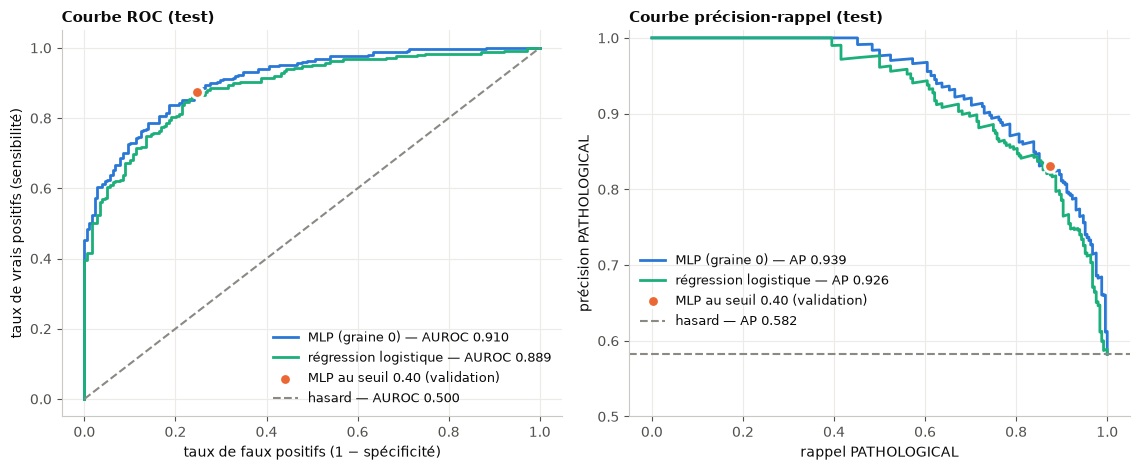

In [33]:
s0 = finaux[0]["p_test"]
prevalence = y["test"].mean()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8))
for scores, nom, couleur, style in ((s0, "MLP (graine 0)", BLEU, "-"), (p_test_logistique, "régression logistique", AQUA, "-")):
    fpr, tpr, _ = roc_curve(y["test"], scores)
    ax1.plot(fpr, tpr, color=couleur, linestyle=style, label=f"{nom} — AUROC {roc_auc_score(y['test'], scores):.3f}")
    precision, rappel, _ = precision_recall_curve(y["test"], scores)
    ax2.plot(rappel, precision, color=couleur, linestyle=style,
             label=f"{nom} — AP {average_precision_score(y['test'], scores):.3f}")
# Point de fonctionnement du MLP au seuil choisi sur la validation.
predit = s0 >= seuil0
vp, fp = (predit & (y["test"] == 1)).sum(), (predit & (y["test"] == 0)).sum()
ax1.scatter(fp / (y["test"] == 0).sum(), vp / (y["test"] == 1).sum(), s=70, color=ORANGE, edgecolor="white",
            linewidth=2, zorder=3, label=f"MLP au seuil {seuil0:.2f} (validation)")
ax2.scatter(vp / (y["test"] == 1).sum(), vp / predit.sum(), s=70, color=ORANGE, edgecolor="white",
            linewidth=2, zorder=3, label=f"MLP au seuil {seuil0:.2f} (validation)")
# Repères : un score tiré au hasard suit la diagonale ROC et la prévalence en précision-rappel.
ax1.plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1.5, label="hasard — AUROC 0.500")
ax2.axhline(prevalence, color=GRIS, linestyle="--", linewidth=1.5, label=f"hasard — AP {prevalence:.3f}")
ax1.set(xlabel="taux de faux positifs (1 − spécificité)", ylabel="taux de vrais positifs (sensibilité)",
        title="Courbe ROC (test)")
ax2.set(xlabel="rappel PATHOLOGICAL", ylabel="précision PATHOLOGICAL", ylim=(0.5, 1.01),
        title="Courbe précision-rappel (test)")
ax1.legend(loc="lower right", fontsize=9)
ax2.legend(loc="lower left", bbox_to_anchor=(0.0, 0.2), fontsize=9)
fig.tight_layout()
plt.show()

### 7.4 Matrice de confusion et distribution des scores

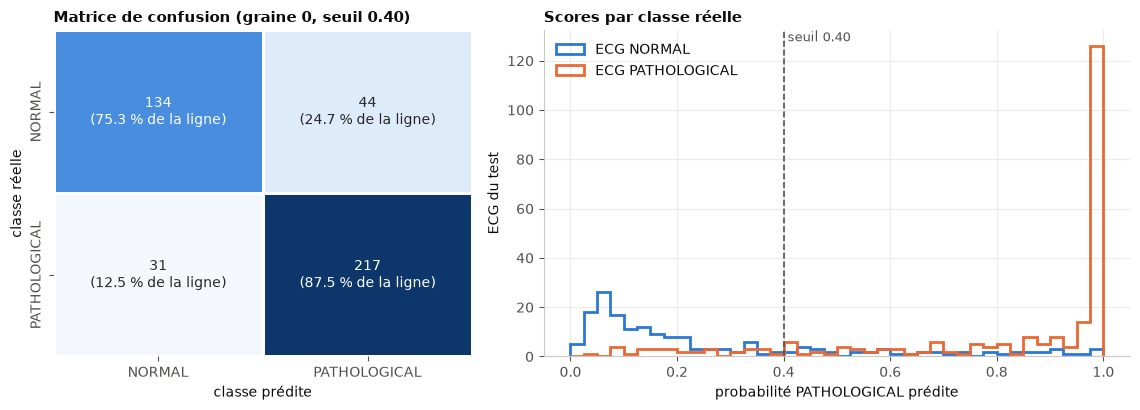

In [34]:
predictions0 = finaux[0]["predictions"]
matrice = confusion_matrix(y["test"], predictions0)
pourcentages = 100 * matrice / matrice.sum(axis=1, keepdims=True)
annotations = [[f"{matrice[i, j]}\n({pourcentages[i, j]:.1f} % de la ligne)" for j in range(2)] for i in range(2)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(matrice, annot=annotations, fmt="", cmap=SEQUENTIEL, cbar=False, linewidths=2, linecolor="white",
            xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={"fontsize": 10}, ax=ax1)
ax1.set(xlabel="classe prédite", ylabel="classe réelle", title=f"Matrice de confusion (graine 0, seuil {seuil0:.2f})")

bacs = np.linspace(0, 1, 41)
for etiquette, classe in enumerate(CLASSES):
    ax2.hist(s0[y["test"] == etiquette], bins=bacs, histtype="step", linewidth=2,
             color=COULEUR_CLASSE[classe], label=f"ECG {classe}")
ax2.axvline(seuil0, color=ENCRE_2, linestyle="--", linewidth=1.2)
ax2.text(seuil0, ax2.get_ylim()[1], f" seuil {seuil0:.2f}", va="top", fontsize=9, color=ENCRE_2)
ax2.set(xlabel="probabilité PATHOLOGICAL prédite", ylabel="ECG du test", title="Scores par classe réelle")
ax2.legend(loc="upper left")
fig.tight_layout()
plt.show()

## 8. Analyse des erreurs

Quels ECG le modèle manque-t-il, et lesquels signale-t-il à tort ? Les taux sont moyennés sur les cinq graines (± écart-type entre graines). Sur un sous-échantillon, certains groupes sont petits : la colonne `ECG` indique l'effectif sur lequel repose chaque taux.

### 8.1 Selon la pathologie

Les superclasses sources, conservées dans les données, permettent de calculer le rappel par pathologie.

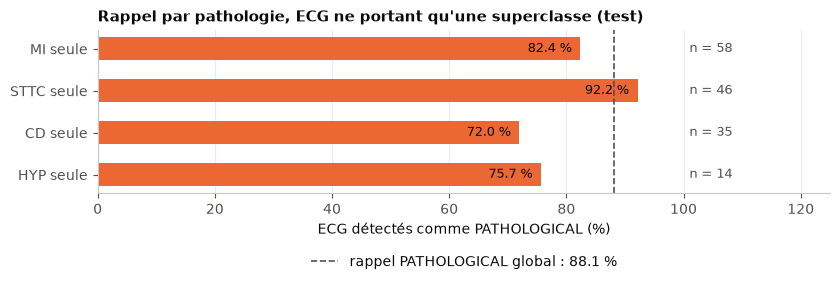

,ECG,prédits PATHOLOGICAL (%),écart-type (points)
MI seule,58,82.4,4.3
STTC seule,46,92.2,3.6
CD seule,35,72.0,4.2
HYP seule,14,75.7,6.4
MI (avec ou sans autre),119,89.7,1.5
STTC (avec ou sans autre),102,95.9,1.9
CD (avec ou sans autre),96,87.9,2.3
HYP (avec ou sans autre),54,91.9,2.1
1 superclasse pathologique,153,82.4,0.8
2 superclasses,69,96.5,1.7


In [35]:
predictions = np.stack([f["predictions"] for f in finaux.values()])  # (graines, ECG)
nb_patho_test = test[PATHOLOGIES].sum(axis=1)
groupes = {f"{c} seule": (test[c] == 1) & (nb_patho_test == 1) for c in PATHOLOGIES}
groupes |= {f"{c} (avec ou sans autre)": test[c] == 1 for c in PATHOLOGIES}
groupes |= {"1 superclasse pathologique": nb_patho_test == 1, "2 superclasses": nb_patho_test == 2,
            "3 ou 4 superclasses": nb_patho_test >= 3,
            "co-étiqueté NORM + pathologie": (test["NORM"] == 1) & (nb_patho_test >= 1)}


def taux_positifs(masque):
    par_graine = predictions[:, np.asarray(masque)].mean(axis=1)
    return {"ECG": int(np.sum(masque)), "prédits PATHOLOGICAL (%)": 100 * par_graine.mean(),
            "écart-type (points)": 100 * par_graine.std(ddof=1)}


rappels = pd.DataFrame({nom: taux_positifs(m) for nom, m in groupes.items() if m.sum() > 0}).T
rappels["ECG"] = rappels["ECG"].astype(int)

seules = rappels.loc[[f"{c} seule" for c in PATHOLOGIES if f"{c} seule" in rappels.index]]
rappel_global = 100 * mlp_test["rappel PATHO"].mean()
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.barh(seules.index, seules["prédits PATHOLOGICAL (%)"], height=0.55, color=ORANGE)
for i, (taux, n) in enumerate(zip(seules["prédits PATHOLOGICAL (%)"], seules["ECG"])):
    ax.text(taux - 1.5, i, f"{taux:.1f} %", ha="right", va="center", fontsize=9)
    ax.text(101, i, f"n = {n}", va="center", fontsize=9, color=ENCRE_2)
ax.axvline(rappel_global, color=ENCRE_2, linestyle="--", linewidth=1.2,
           label=f"rappel PATHOLOGICAL global : {rappel_global:.1f} %")
ax.invert_yaxis()
ax.set_xlim(0, 125)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3))
ax.set_xlabel("ECG détectés comme PATHOLOGICAL (%)")
ax.set_title("Rappel par pathologie, ECG ne portant qu'une superclasse (test)")
fig.tight_layout()
plt.show()
rappels.round(1)

### 8.2 Selon l'âge et le sexe

Parmi les ECG `NORMAL`, une erreur est un faux positif ; parmi les ECG `PATHOLOGICAL`, un faux négatif. L'âge et le sexe ne sont pas des entrées du modèle : on regarde seulement si ses erreurs en dépendent.

,faux positifs parmi les NORMAL (%),n NORMAL,faux négatifs parmi les PATHOLOGICAL (%),n PATHOLOGICAL
tranche d'âge,,,,
< 40 ans,15.8,57,53.3,9
40–59 ans,29.1,66,19.7,60
60–74 ans,38.5,40,8.2,117
≥ 75 ans,50.7,15,5.5,62


,faux positifs parmi les NORMAL (%),n NORMAL,faux négatifs parmi les PATHOLOGICAL (%),n PATHOLOGICAL
sexe,,,,
femme,27.8,102,10.3,99
homme,30.0,76,13.0,149


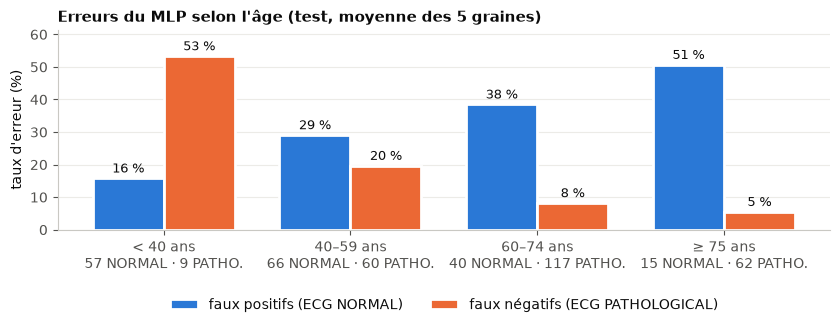

In [36]:
profil = test[["classe", "age", "sex"]].copy()
# PTB-XL code les âges > 89 ans par 300 (anonymisation) : ils tombent dans la dernière tranche.
profil["tranche d'âge"] = pd.cut(profil["age"], [0, 40, 60, 75, np.inf], right=False,
                                 labels=["< 40 ans", "40–59 ans", "60–74 ans", "≥ 75 ans"])
profil["sexe"] = profil["sex"].map({0: "homme", 1: "femme"})
profil["erreur (%)"] = 100 * (predictions != y["test"]).mean(axis=0)


def erreurs_par(variable):
    table = profil.groupby([variable, "classe"], observed=True)["erreur (%)"].agg(["mean", "size"]).unstack("classe")
    return pd.DataFrame({"faux positifs parmi les NORMAL (%)": table[("mean", "NORMAL")],
                         "n NORMAL": table[("size", "NORMAL")],
                         "faux négatifs parmi les PATHOLOGICAL (%)": table[("mean", "PATHOLOGICAL")],
                         "n PATHOLOGICAL": table[("size", "PATHOLOGICAL")]})


par_age, par_sexe = erreurs_par("tranche d'âge"), erreurs_par("sexe")
display(par_age.round(1), par_sexe.round(1))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
positions, largeur = np.arange(len(par_age)), 0.38
for decalage, colonne, couleur, nom in (
        (-largeur / 2, "faux positifs parmi les NORMAL (%)", BLEU, "faux positifs (ECG NORMAL)"),
        (largeur / 2, "faux négatifs parmi les PATHOLOGICAL (%)", ORANGE, "faux négatifs (ECG PATHOLOGICAL)")):
    barres = ax.bar(positions + decalage, par_age[colonne], width=largeur, color=couleur,
                    edgecolor="white", linewidth=2, label=nom)
    ax.bar_label(barres, fmt="%.0f %%", fontsize=9, padding=2)
ax.set_xticks(positions, [f"{tranche}\n{n_normal} NORMAL · {n_patho} PATHO."
                          for tranche, n_normal, n_patho in zip(par_age.index, par_age["n NORMAL"], par_age["n PATHOLOGICAL"])])
ax.set_ylabel("taux d'erreur (%)")
ax.set_ylim(0, 1.15 * par_age[["faux positifs parmi les NORMAL (%)", "faux négatifs parmi les PATHOLOGICAL (%)"]].max().max())
ax.grid(axis="x", visible=False)
ax.legend(ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.28))
ax.set_title(f"Erreurs du MLP selon l'âge (test, moyenne des {len(GRAINES)} graines)")
fig.tight_layout()
plt.show()

### 8.3 Les erreurs les plus confiantes

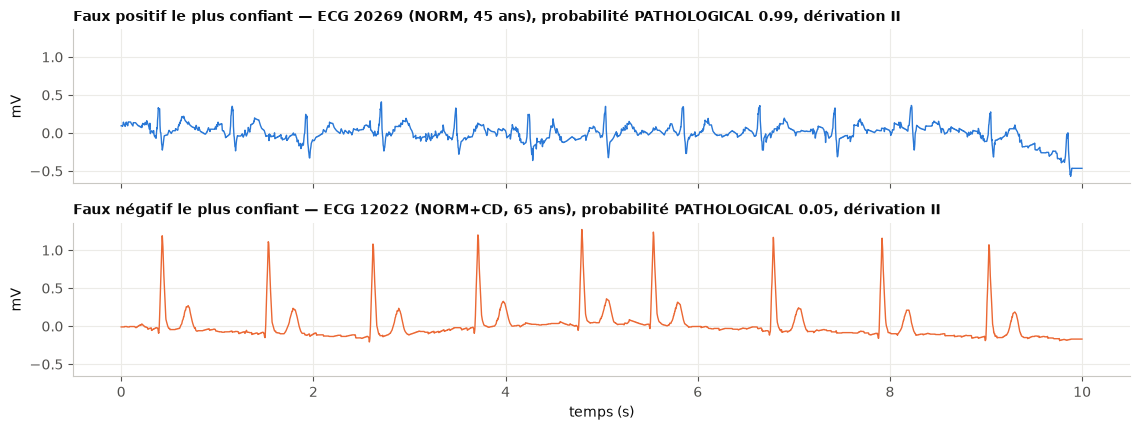

In [37]:
masque_fp, masque_fn = (y["test"] == 0) & (predictions0 == 1), (y["test"] == 1) & (predictions0 == 0)
cas = {"Faux positif le plus confiant": test[masque_fp].assign(score=s0[masque_fp]).nlargest(1, "score").iloc[0],
       "Faux négatif le plus confiant": test[masque_fn].assign(score=s0[masque_fn]).nsmallest(1, "score").iloc[0]}
fig, axes = plt.subplots(2, 1, figsize=(11.5, 4.4), sharex=True, sharey=True)
for ax, (titre, ligne) in zip(axes, cas.items()):
    superclasses = "+".join(c for c in SUPERCLASSES if ligne[c] == 1)
    ax.plot(temps, lire_ecg(DOSSIER_PTBXL / ligne["filename_hr"])[:, DERIVATIONS.index("II")],
            color=COULEUR_CLASSE[ligne["classe"]], linewidth=1)
    ax.set_title(f"{titre} — ECG {ligne['ecg_id']} ({superclasses}, {ligne['age']:.0f} ans), "
                 f"probabilité PATHOLOGICAL {ligne['score']:.2f}, dérivation II", fontsize=10)
    ax.set_ylabel("mV")
axes[-1].set_xlabel("temps (s)")
fig.tight_layout()
plt.show()

**Lecture de l'analyse des erreurs.** Les effectifs sont petits sur ce sous-échantillon, mais les tendances sont celles observées sur la base complète.

- **Les erreurs se concentrent sur les cas « purs ».** Quand un ECG ne porte qu'une superclasse pathologique, le rappel tombe à 82 % ; il atteint 96 % avec deux superclasses et 99 % avec trois ou quatre. Le modèle détecte surtout les tracés franchement anormaux.
- **Par pathologie** (ECG à superclasse unique), STTC est la mieux détectée (92 %), devant MI (82 %), HYP (76 %, sur 14 ECG seulement) et CD (72 %). Hypothèse : un trouble de conduction ou un infarctus ancien se lisent sur des signes localisés (élargissement du QRS, ondes Q sur certaines dérivations), que des statistiques globales sur 10 s résument mal, alors que les anomalies de ST et de T déplacent le niveau du tracé, que la médiane capte (§ 4.4).
- **Les ECG co-étiquetés NORM et pathologie** ne sont détectés qu'à 43 % (8 ECG ici ; 52 % sur les 40 ECG du test complet). L'annotateur lui-même les jugeait en partie normaux : une part de ces « erreurs » relève de l'ambiguïté de l'étiquette.
- **L'âge est un facteur de confusion majeur.** Parmi les ECG normaux, le taux de faux positifs passe de 16 % avant 40 ans à 51 % après 75 ans ; parmi les ECG pathologiques, le taux de faux négatifs passe à l'inverse de 53 % avant 40 ans (sur 9 ECG seulement) à 5 % après 75 ans. Le modèle a en partie appris les modifications de l'ECG liées à l'âge, elles-mêmes corrélées à la pathologie dans PTB-XL : un ECG normal de personne âgée « ressemble » à un ECG pathologique, et un ECG pathologique de personne jeune passe plus souvent inaperçu. L'écart selon le sexe est faible.
- **Les erreurs les plus confiantes** illustrent deux limites. Le faux positif est un ECG annoté NORM, de faible amplitude et bruité sur la dérivation II, que le modèle juge pathologique avec une probabilité de 0,99 : des statistiques d'amplitude distinguent mal un tracé simplement peu ample ou bruité d'un tracé anormal. Le faux négatif est co-étiqueté NORM et CD : un cas limite, que l'annotateur jugeait en partie normal, et dont la dérivation II paraît régulière.

## 9. Prédiction sur un nouvel ECG

La fonction `predire` enchaîne tout le pipeline pour un enregistrement WFDB quelconque : lecture et contrôle du signal, 120 caractéristiques, prétraitement ajusté sur le train, puis les cinq MLP, chacun avec son seuil. La décision finale est celle de la majorité des cinq graines.

On l'applique à des ECG des **folds 7 à 9**, jamais utilisés ni pour l'entraînement, ni pour le réglage, ni pour le test.

In [38]:
def predire(chemin):
    """Probabilité PATHOLOGICAL et décision de chaque graine, puis vote, pour un enregistrement WFDB 500 Hz."""
    entree = prep.transform(pd.DataFrame([caracteristiques_ecg(lire_ecg(chemin))])[CARACTERISTIQUES].to_numpy())
    par_graine = {g: float(probabilites(f["modele"], entree)[0, 1]) for g, f in finaux.items()}
    votes = sum(p >= finaux[g]["seuil"] for g, p in par_graine.items())
    return {"probabilité PATHOLOGICAL (moyenne)": np.mean(list(par_graine.values())),
            "votes PATHOLOGICAL": f"{votes} / {len(finaux)}",
            "décision": CLASSES[int(votes > len(finaux) / 2)]}


nouveaux = hors_partitions.groupby("classe", group_keys=False).sample(n=3, random_state=GRAINE_ECHANTILLON)
assurer_fichiers([f"{fichier}{extension}" for fichier in nouveaux["filename_hr"] for extension in (".hea", ".dat")])
pd.DataFrame([{"ECG": ligne["ecg_id"], "fold": ligne["strat_fold"], "âge": ligne["age"],
               "superclasses": "+".join(c for c in SUPERCLASSES if ligne[c] == 1), "classe réelle": ligne["classe"],
               **predire(DOSSIER_PTBXL / ligne["filename_hr"])}
              for _, ligne in nouveaux.iterrows()]).set_index("ECG").round(3)

12 fichiers présents dans data\raw\ptb-xl : aucun téléchargement.


,fold,âge,superclasses,classe réelle,probabilité PATHOLOGICAL (moyenne),votes PATHOLOGICAL,décision
ECG,,,,,,,
16894,7,47.0,NORM,NORMAL,0.089,0 / 5,NORMAL
9846,7,61.0,NORM,NORMAL,0.411,3 / 5,PATHOLOGICAL
10378,7,59.0,NORM,NORMAL,0.096,0 / 5,NORMAL
5296,9,56.0,MI,PATHOLOGICAL,0.492,5 / 5,PATHOLOGICAL
18804,9,41.0,HYP,PATHOLOGICAL,0.516,5 / 5,PATHOLOGICAL
11458,8,76.0,STTC+HYP,PATHOLOGICAL,0.934,5 / 5,PATHOLOGICAL


## 10. Comparaison avec la base complète

### 10.1 Ce notebook face à l'entraînement du projet

Le projet a été entraîné et évalué sur la base complète : 10 692 ECG d'entraînement, 2 158 de validation, 2 129 de test (fichiers `protocol.json`, `cross_validation/summary.json` et `test_summary.json` de `results/binary/`). Le tableau met en regard ces résultats et ceux de cette exécution.

Sur la base complète (archive officielle décompressée dans `DOSSIER_PTBXL`, `N_ECG = None`), le notebook refait ce protocole et retrouve ces valeurs à quelques millièmes près (AUROC test 0,9052 ± 0,0009, F1 macro 0,8073 ± 0,0063, validation croisée 0,8968 ± 0,0064). Le seuil d'une graine peut différer de quelques centièmes : l'entraînement du projet partait de caractéristiques enregistrées avec 12 chiffres significatifs, et ces infimes écarts suffisent à déplacer le maximum d'un F1 presque plat.

In [39]:
REFERENCE_BASE_COMPLETE = {  # moyennes ± écarts-types sur les 5 graines, base complète (results/binary/)
    "ECG d'entraînement": "10692",
    "ECG de test": "2129",
    "AUROC validation": "0.8793 ± 0.0016",
    "AUROC validation croisée imbriquée": "0.8967 ± 0.0068",
    "AUROC test": "0.9050 ± 0.0008",
    "IC 95 % AUROC test (bootstrap)": "0.891 – 0.919",
    "F1 macro test": "0.8061 ± 0.0089",
    "exactitude test": "0.8149 ± 0.0073",
    "précision PATHO test": "0.8150 ± 0.0129",
    "rappel PATHO test": "0.8826 ± 0.0086",
    "rappel NORMAL test": "0.7207 ± 0.0264",
}
ce_notebook = {
    "ECG d'entraînement": str(len(train)),
    "ECG de test": str(len(test)),
    "AUROC validation": moyenne_ecart([roc_auc_score(y["validation"], f["p_val"]) for f in finaux.values()]),
    "AUROC validation croisée imbriquée": moyenne_ecart(validation_croisee["AUROC"]),
    "AUROC test": moyenne_ecart(mlp_test["AUROC"]),
    "IC 95 % AUROC test (bootstrap)": f"{tirages['AUROC MLP'].quantile(0.025):.3f} – {tirages['AUROC MLP'].quantile(0.975):.3f}",
    **{f"{m} test": moyenne_ecart(mlp_test[m]) for m in ("F1 macro", "exactitude", "précision PATHO",
                                                          "rappel PATHO", "rappel NORMAL")},
}
pd.DataFrame({f"ce notebook ({len(selection)} ECG)": ce_notebook,
              "base complète (14 979 ECG)": REFERENCE_BASE_COMPLETE})

,ce notebook (3000 ECG),base complète (14 979 ECG)
ECG d'entraînement,2141,10692
ECG de test,426,2129
AUROC validation,0.8809 ± 0.0024,0.8793 ± 0.0016
AUROC validation croisée imbriquée,0.8676 ± 0.0114,0.8967 ± 0.0068
AUROC test,0.9027 ± 0.0057,0.9050 ± 0.0008
IC 95 % AUROC test (bootstrap),0.873 – 0.928,0.891 – 0.919
F1 macro test,0.8010 ± 0.0137,0.8061 ± 0.0089
exactitude test,0.8103 ± 0.0112,0.8149 ± 0.0073
précision PATHO test,0.8106 ± 0.0187,0.8150 ± 0.0129
rappel PATHO test,0.8806 ± 0.0088,0.8826 ± 0.0086


### 10.2 Effet de la taille de l'échantillon d'entraînement

Combien la performance dépend-elle du nombre d'ECG d'entraînement ? On réentraîne le MLP sur des fractions croissantes du train (10 %, 25 %, 50 % et 100 %, trois graines par fraction), et on mesure l'AUROC sur la même validation. Le test n'est pas réutilisé.

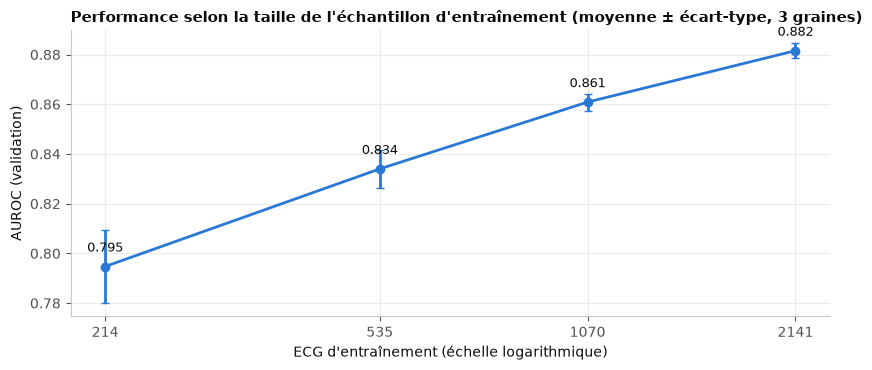

,mean,std
ECG d'entraînement,,
214,0.7947,0.0149
535,0.8340,0.0076
1070,0.8609,0.0034
2141,0.8816,0.0030


In [40]:
FRACTIONS = (0.1, 0.25, 0.5, 1.0)
# Ordre aléatoire fixe des ECG de chaque classe : chaque fraction contient la précédente
# et conserve la proportion de classes du train.
rng_taille = np.random.default_rng(GRAINE_ECHANTILLON)
ordre_par_classe = [rng_taille.permutation(np.flatnonzero(y["train"] == c)) for c in (0, 1)]
lignes = []
for fraction in FRACTIONS:
    indices = np.sort(np.concatenate([ordre[: int(round(fraction * len(ordre)))] for ordre in ordre_par_classe]))
    prep_fraction = pretraitement().fit(X["train"][indices])
    for graine in (0, 1, 2):
        _, p_val, _, _ = entrainer_mlp(CONFIG_FINALE, graine, prep_fraction.transform(X["train"][indices]), y["train"][indices],
                                       prep_fraction.transform(X["validation"]), y["validation"])
        lignes.append({"ECG d'entraînement": len(indices), "graine": graine, "AUROC validation": roc_auc_score(y["validation"], p_val)})
taille = pd.DataFrame(lignes).groupby("ECG d'entraînement")["AUROC validation"].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.errorbar(taille.index, taille["mean"], yerr=taille["std"], color=BLEU, marker="o", capsize=3)
for n, auroc in taille["mean"].items():
    ax.text(n, auroc + 0.006, f"{auroc:.3f}", ha="center", fontsize=9)
ax.set_xscale("log")
ax.set_xticks(taille.index, [str(n) for n in taille.index])
ax.minorticks_off()
ax.set_xlabel("ECG d'entraînement (échelle logarithmique)")
ax.set_ylabel("AUROC (validation)")
ax.set_title("Performance selon la taille de l'échantillon d'entraînement (moyenne ± écart-type, 3 graines)")
fig.tight_layout()
plt.show()
taille.round(4)

**Lecture.**

- **Sur la même validation**, l'AUROC progresse régulièrement avec la taille du train : 0,795 avec 214 ECG, 0,834 avec 535, 0,861 avec 1 070 et 0,882 avec 2 141, soit +0,02 à +0,04 à chaque doublement, sans plateau visible à cette échelle.
- **Au-delà, le gain s'essouffle.** Avec `N_ECG = None`, la même expérience donne 0,835 (1 069 ECG), 0,860 (2 674), 0,874 (5 346) et 0,879 (10 692) : chaque palier rapporte de moins en moins (+0,025, +0,014, puis +0,005). Avec ces 120 statistiques globales, ajouter des ECG n'apporterait plus beaucoup ; il faudrait des caractéristiques plus riches (§ 11).
- **Face à la base complète (§ 10.1)**, la comparaison la plus juste est la validation croisée imbriquée, qui suit le même protocole et évalue tout le train : 0,868 avec environ 1 700 ECG d'entraînement par pli, contre 0,897 avec environ 8 550. Passer de 3 000 à 14 979 ECG apporte donc environ +0,03 d'AUROC. Les AUROC de validation et de test, elles, sont presque identiques dans les deux colonnes ; cette proximité tient au hasard du tirage de petits ensembles d'évaluation (le sous-test est plus facile que le test complet, § 7.2), pas à une absence d'effet de la taille.
- **Le reste du protocole se transpose** : mêmes tendances dans la grille d'hyperparamètres, même compromis de seuil (rappel `PATHOLOGICAL` 0,88, rappel `NORMAL` 0,71 à 0,72), mêmes erreurs dominantes.

## 11. Conclusion

**Résultat.** Sur un sous-échantillon stratifié de 3 000 ECG (20 % de PTB-XL), le pipeline complet, des fichiers WFDB bruts jusqu'à la prédiction, fonctionne de bout en bout en une dizaine de minutes. Le MLP 120–128–64–2, entraîné sur les 120 statistiques globales de 2 141 ECG, distingue les ECG normaux des ECG pathologiques avec une AUROC de 0,903 (IC 95 % : 0,873–0,928) et un F1 macro de 0,801, sur 426 ECG de test jamais utilisés pour le réglage. La validation croisée imbriquée, plus prudente, donne 0,868 ± 0,011.

**Effet de la quantité de données.** Ces chiffres de test sont proches de ceux de la base complète (AUROC 0,905, F1 macro 0,806), mais cette proximité tient en partie au tirage : à protocole égal, passer de 3 000 à 14 979 ECG apporte environ +0,03 d'AUROC (validation croisée : 0,868 → 0,897). Mais sur la base complète, le gain s'essouffle au-delà de 5 000 ECG d'entraînement (§ 10.2) : pour aller plus loin, il faudra des caractéristiques plus riches plutôt que davantage d'ECG.

**Interprétation métier.** Au seuil retenu, sur 100 ECG pathologiques, le modèle en signale environ 88 et en manque 12 ; sur 100 ECG normaux, il déclenche environ 29 fausses alertes. Un tel outil pourrait au mieux aider à **trier** les tracés à relire en priorité ; il ne pose pas de diagnostic. Le seuil est un choix métier, pas technique : en dépistage, où manquer une pathologie coûte plus cher qu'une fausse alerte, on l'abaisserait pour gagner en sensibilité, au prix de davantage de fausses alertes (§ 6.4). Les performances dépendent aussi fortement de l'âge : le même seuil donne environ une fausse alerte sur deux chez les personnes normales de plus de 75 ans.

**Limites.**

- Les 120 statistiques globales ignorent la morphologie et la chronologie des battements : ondes P, QRS et T, intervalles PR et QT ne sont pas mesurés.
- La cible binaire fusionne quatre familles de pathologies de gravité très différente ; le modèle n'en indique ni le type ni la gravité.
- Le MLP ne devance la régression logistique que de 0,013 d'AUROC ici (écart non significatif sur 426 ECG) et de 0,020 sur la base complète : la non-linéarité apporte un gain réel mais modeste, l'essentiel de l'information étant déjà accessible à un modèle linéaire.
- Une seule base et un seul fold de test. Les auteurs de PTB-XL recommandent les folds 9 et 10, dont les étiquettes ont été validées manuellement, comme validation et test ; le projet garde le fold 10 pour la validation mais teste sur le fold 6.
- Les probabilités ne sont pas calibrées : une sortie de 0,8 ne signifie pas « 80 % de risque ».
- L'âge, absent des entrées, agit comme un facteur de confusion.

**Pistes d'amélioration.**

- Ajouter des caractéristiques morphologiques par battement : détection des QRS, durées, amplitudes, décalage du segment ST.
- Entraîner un réseau convolutif sur le signal brut, l'approche de référence sur PTB-XL.
- Comparer à un ensemble d'arbres (gradient boosting), souvent très performant sur des variables tabulaires.
- Fournir l'âge et le sexe au modèle, ou régler un seuil par tranche d'âge.
- Calibrer les probabilités, puis valider le modèle sur une base externe avant toute revendication de généralisation.

In [41]:
print(f"Durée totale d'exécution : {(time.perf_counter() - DEBUT_NOTEBOOK) / 60:.1f} min "
      f"({len(selection)} ECG)")

Durée totale d'exécution : 5.7 min (3000 ECG)
